<div align="center">

# Universidad Autónoma del Estado de México
## Centro Universitario UAEM Zumpango
### Ingeniería en Computación

---

# ACTIVIDAD INTEGRADORA
## Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook

**Asignatura:** Investigación de Operaciones  
**Periodo:** 2026B  
**Modalidad:** Trabajo colaborativo por equipos

**Prácticas incluidas:**  
1. Algoritmo de Expansión Mínima (Kruskal)  
2. Ruta Crítica (PERT/CPM)  
3. Algoritmo de Dijkstra  
4. Programación Lineal

**Integrantes:**  
Karla Isabel Bautista Santillán  
Johan Palmero Vargas  
Enrique Donovan Barrera Navarro

**Fecha:** 18 de noviembre de 2026

</div>

---

## Índice

1. [Práctica 1. Árbol de Expansión Mínima (Kruskal)](#practica1)
2. [Práctica 2. Ruta Crítica (PERT/CPM)](#practica2)
3. [Práctica 3. Algoritmo de Dijkstra](#practica3)
4. [Práctica 4. Programación Lineal](#practica4)
5. [Conclusiones individuales y del equipo](#conclusiones)

**Estructura de cada práctica:** descripción del problema → formulación matemática → importación de bibliotecas → definición de datos → desarrollo del algoritmo → ejecución paso a paso → visualización de resultados → análisis final.

## 0. Importación de bibliotecas (comunes a todas las prácticas)

Se usan las herramientas indicadas en la actividad:

| Biblioteca | Para qué se usa |
|---|---|
| `numpy` | Operaciones numéricas y mallas para graficar |
| `pandas` | Tablas de datos y de resultados |
| `networkx` | Construcción y dibujo de grafos |
| `matplotlib` | Todas las gráficas paso a paso |
| `scipy.optimize.linprog` | Resolver el modelo de programación lineal |
| `heapq`, `math` | Cola de prioridad (Dijkstra) y utilidades |

In [ ]:
import math
import heapq
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display, Markdown

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = False
pd.set_option("display.max_columns", 30)
print("Bibliotecas cargadas correctamente")
print("NetworkX:", nx.__version__, "| NumPy:", np.__version__, "| Pandas:", pd.__version__)

Bibliotecas cargadas correctamente
NetworkX: 3.7 | NumPy: 2.5.4 | Pandas: 3.0.6


<a id="practica1"></a>
---
# PRÁCTICA 1. Árbol de Expansión Mínima (Algoritmo de Kruskal)

## 1.1 Título del problema
**Cableado de costo mínimo para la red de un laboratorio de cómputo.**

## 1.2 Descripción y planteamiento
Un laboratorio de cómputo cuenta con **8 dispositivos de red**: un servidor (`SRV`), un router (`RTR`), tres switches (`SW-A`, `SW-B`, `SW-C`), dos puntos de acceso inalámbricos (`AP-1`, `AP-2`) y un almacenamiento en red (`NAS`). Existen **13 enlaces posibles** de cableado; cada uno tiene un costo (en cientos de pesos, por material e instalación).

**Objetivo:** conectar *todos* los dispositivos entre sí con el menor costo total de cableado, sin crear ciclos (un ciclo sería un enlace redundante que encarece la instalación).

## 1.3 Formulación matemática
Sea $G=(V,E)$ un grafo no dirigido y ponderado con $|V|=8$ nodos y pesos $w(e)>0$.  
Se busca un subconjunto $T\subseteq E$ tal que:

$$\min \sum_{e\in T} w(e)$$

sujeto a que $T$ conecte todos los nodos y no contenga ciclos. Un árbol de expansión de $n$ nodos tiene exactamente $n-1$ aristas, es decir, **7 aristas** en este caso.

**Algoritmo de Kruskal (criterio voraz):**
1. Ordenar todas las aristas de menor a mayor peso.
2. Recorrer la lista; agregar la arista si **no forma un ciclo** con las ya elegidas.
3. Detenerse cuando haya $n-1$ aristas.

Para detectar ciclos se usa la estructura **Union-Find** (conjuntos disjuntos): si los dos extremos de la arista ya pertenecen al mismo conjunto, agregarla crearía un ciclo.

## 1.4 Definición de datos
Se define la lista de aristas `(origen, destino, costo)` y se construye el grafo con NetworkX. También se fija una **posición única** de los nodos para que todas las gráficas se vean igual y se pueda comparar paso a paso.

In [2]:
aristas = [
    ("RTR",  "SW-A", 2), ("SW-C", "AP-2", 2), ("SRV",  "NAS", 3),
    ("SW-A", "SW-B", 3), ("RTR",  "SRV",  4), ("SW-B", "SW-C", 4),
    ("SRV",  "SW-A", 5), ("SW-B", "AP-1", 5), ("RTR",  "SW-B", 6),
    ("AP-1", "AP-2", 6), ("SW-A", "SW-C", 7), ("NAS",  "SW-C", 8),
    ("AP-1", "SW-A", 9),
]

G1 = nx.Graph()
G1.add_weighted_edges_from(aristas)

pos1 = {"RTR": (0, 0), "SRV": (-2, 1.2), "NAS": (-3, -0.6), "SW-A": (1.3, 1.5),
        "SW-B": (2.6, 0), "SW-C": (1.3, -1.8), "AP-1": (4, 1.3), "AP-2": (3.3, -1.8)}

df_aristas = pd.DataFrame(aristas, columns=["Origen", "Destino", "Costo"])
print(f"Nodos: {G1.number_of_nodes()} | Aristas posibles: {G1.number_of_edges()}")
display(df_aristas)

Nodos: 8 | Aristas posibles: 13


,Origen,Destino,Costo
0,RTR,SW-A,2
1,SW-C,AP-2,2
2,SRV,NAS,3
3,SW-A,SW-B,3
4,RTR,SRV,4
5,SW-B,SW-C,4
6,SRV,SW-A,5
7,SW-B,AP-1,5
8,RTR,SW-B,6
9,AP-1,AP-2,6


### Función auxiliar de dibujo
Esta función se reutiliza en cada paso: dibuja el grafo completo en gris, las aristas ya aceptadas en **verde**, y la arista que se está evaluando en **naranja** (si se acepta) o **rojo punteado** (si se rechaza por formar un ciclo).

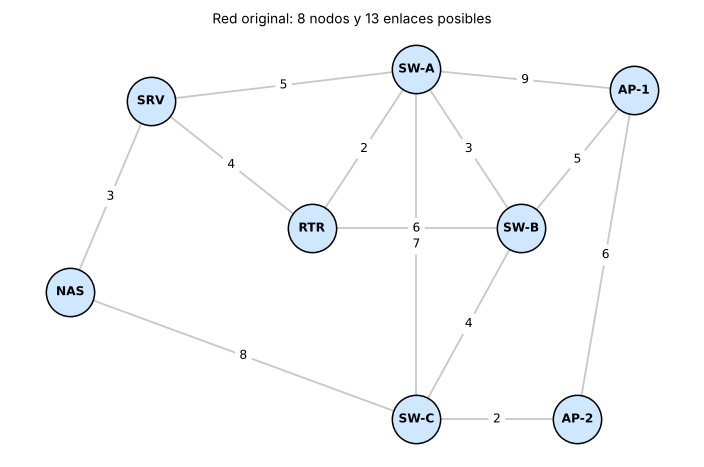

In [3]:
def dibujar_mst(ax, G, pos, aceptadas=(), evaluada=None, rechazada=False, titulo=""):
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#cfe8ff", edgecolors="black", node_size=1000)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight="bold")
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c8c8c8", width=1.2)
    if aceptadas:
        nx.draw_networkx_edges(G, pos, edgelist=list(aceptadas), ax=ax, edge_color="green", width=4)
    if evaluada is not None:
        nx.draw_networkx_edges(G, pos, edgelist=[evaluada], ax=ax,
                               edge_color="red" if rechazada else "orange",
                               width=3.5, style="dashed" if rechazada else "solid")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"),
                                 ax=ax, font_size=8, rotate=False)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(8, 5))
dibujar_mst(ax, G1, pos1, titulo="Red original: 8 nodos y 13 enlaces posibles")
plt.show()

## 1.5 Desarrollo del algoritmo

### Paso 1. Ordenar las aristas por costo
Kruskal es un algoritmo **voraz**: siempre considera primero las aristas más baratas.

,Origen,Destino,Costo
Orden,,,
1,RTR,SW-A,2
2,SW-C,AP-2,2
3,SRV,NAS,3
4,SW-A,SW-B,3
5,RTR,SRV,4
6,SW-B,SW-C,4
7,SRV,SW-A,5
8,SW-B,AP-1,5
9,RTR,SW-B,6


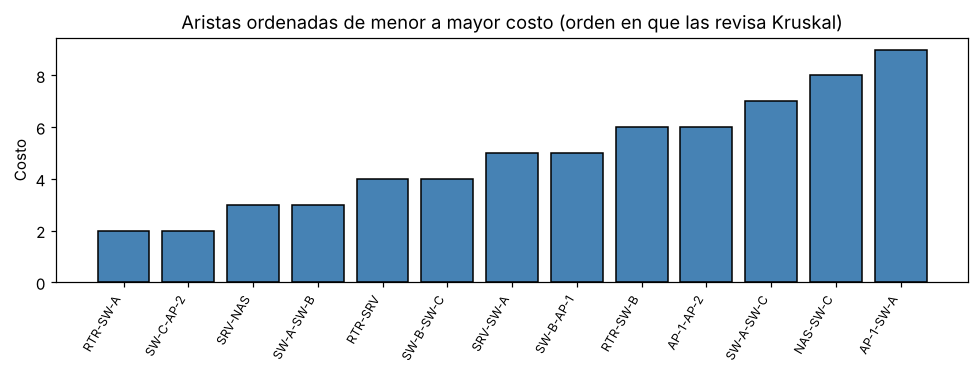

In [4]:
ordenadas = sorted(aristas, key=lambda e: e[2])
df_orden = pd.DataFrame(ordenadas, columns=["Origen", "Destino", "Costo"])
df_orden.index = range(1, len(df_orden) + 1)
df_orden.index.name = "Orden"
display(df_orden)

fig, ax = plt.subplots(figsize=(9, 3.5))
etiquetas = [f"{u}-{v}" for u, v, _ in ordenadas]
pesos = [w for _, _, w in ordenadas]
ax.bar(etiquetas, pesos, color="steelblue", edgecolor="black")
ax.set_ylabel("Costo")
ax.set_title("Aristas ordenadas de menor a mayor costo (orden en que las revisa Kruskal)")
plt.xticks(rotation=60, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

### Paso 2. Estructura Union-Find
Cada nodo comienza en su propio conjunto. `find(x)` devuelve el representante del conjunto de `x`, y `union(a, b)` fusiona dos conjuntos. Si `find(a) == find(b)`, la arista $(a,b)$ cerraría un ciclo.

In [5]:
padre = {n: n for n in G1.nodes()}

def find(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]   # compresión de caminos
        x = padre[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        padre[rb] = ra
        return True
    return False

print("Conjuntos iniciales (cada nodo es su propio representante):")
print(padre)

Conjuntos iniciales (cada nodo es su propio representante):
{'RTR': 'RTR', 'SW-A': 'SW-A', 'SW-C': 'SW-C', 'AP-2': 'AP-2', 'SRV': 'SRV', 'NAS': 'NAS', 'SW-B': 'SW-B', 'AP-1': 'AP-1'}


### Paso 3. Ejecución paso a paso de Kruskal
Se revisa cada arista en orden. Se imprime la decisión y se guarda una "foto" del estado para graficar cada iteración en el siguiente paso.

In [6]:
padre = {n: n for n in G1.nodes()}          # reiniciar
mst_aristas = []
costo_total = 0
pasos = []                                   # historial para graficar

print(f"{'#':>2} | {'Arista':<14} | {'Costo':>5} | {'Decisión':<28} | Costo acumulado")
print("-" * 80)
for i, (u, v, w) in enumerate(ordenadas, start=1):
    if len(mst_aristas) == G1.number_of_nodes() - 1:
        decision, rechazada = "Omitida (árbol ya completo)", True
        pasos.append(((u, v), w, list(mst_aristas), True, costo_total, decision))
        print(f"{i:>2} | {u+'-'+v:<14} | {w:>5} | {decision:<28} | {costo_total}")
        continue
    if union(u, v):
        mst_aristas.append((u, v))
        costo_total += w
        decision, rechazada = "ACEPTADA", False
    else:
        decision, rechazada = "RECHAZADA (formaría ciclo)", True
    pasos.append(((u, v), w, list(mst_aristas), rechazada, costo_total, decision))
    print(f"{i:>2} | {u+'-'+v:<14} | {w:>5} | {decision:<28} | {costo_total}")

print("-" * 80)
print(f"Aristas en el árbol: {len(mst_aristas)} (se esperaban {G1.number_of_nodes()-1})")
print(f"COSTO MÍNIMO TOTAL = {costo_total}")

 # | Arista         | Costo | Decisión                     | Costo acumulado
--------------------------------------------------------------------------------
 1 | RTR-SW-A       |     2 | ACEPTADA                     | 2
 2 | SW-C-AP-2      |     2 | ACEPTADA                     | 4
 3 | SRV-NAS        |     3 | ACEPTADA                     | 7
 4 | SW-A-SW-B      |     3 | ACEPTADA                     | 10
 5 | RTR-SRV        |     4 | ACEPTADA                     | 14
 6 | SW-B-SW-C      |     4 | ACEPTADA                     | 18
 7 | SRV-SW-A       |     5 | RECHAZADA (formaría ciclo)   | 18
 8 | SW-B-AP-1      |     5 | ACEPTADA                     | 23
 9 | RTR-SW-B       |     6 | Omitida (árbol ya completo)  | 23
10 | AP-1-AP-2      |     6 | Omitida (árbol ya completo)  | 23
11 | SW-A-SW-C      |     7 | Omitida (árbol ya completo)  | 23
12 | NAS-SW-C       |     8 | Omitida (árbol ya completo)  | 23
13 | AP-1-SW-A      |     9 | Omitida (árbol ya completo)  | 23
-------------

## 1.6 Visualización paso a paso
Cada recuadro muestra el estado del algoritmo **después de evaluar una arista**:  
🟢 verde = aristas ya aceptadas · 🟠 naranja = arista aceptada en ese paso · 🔴 rojo punteado = arista rechazada por formar un ciclo.

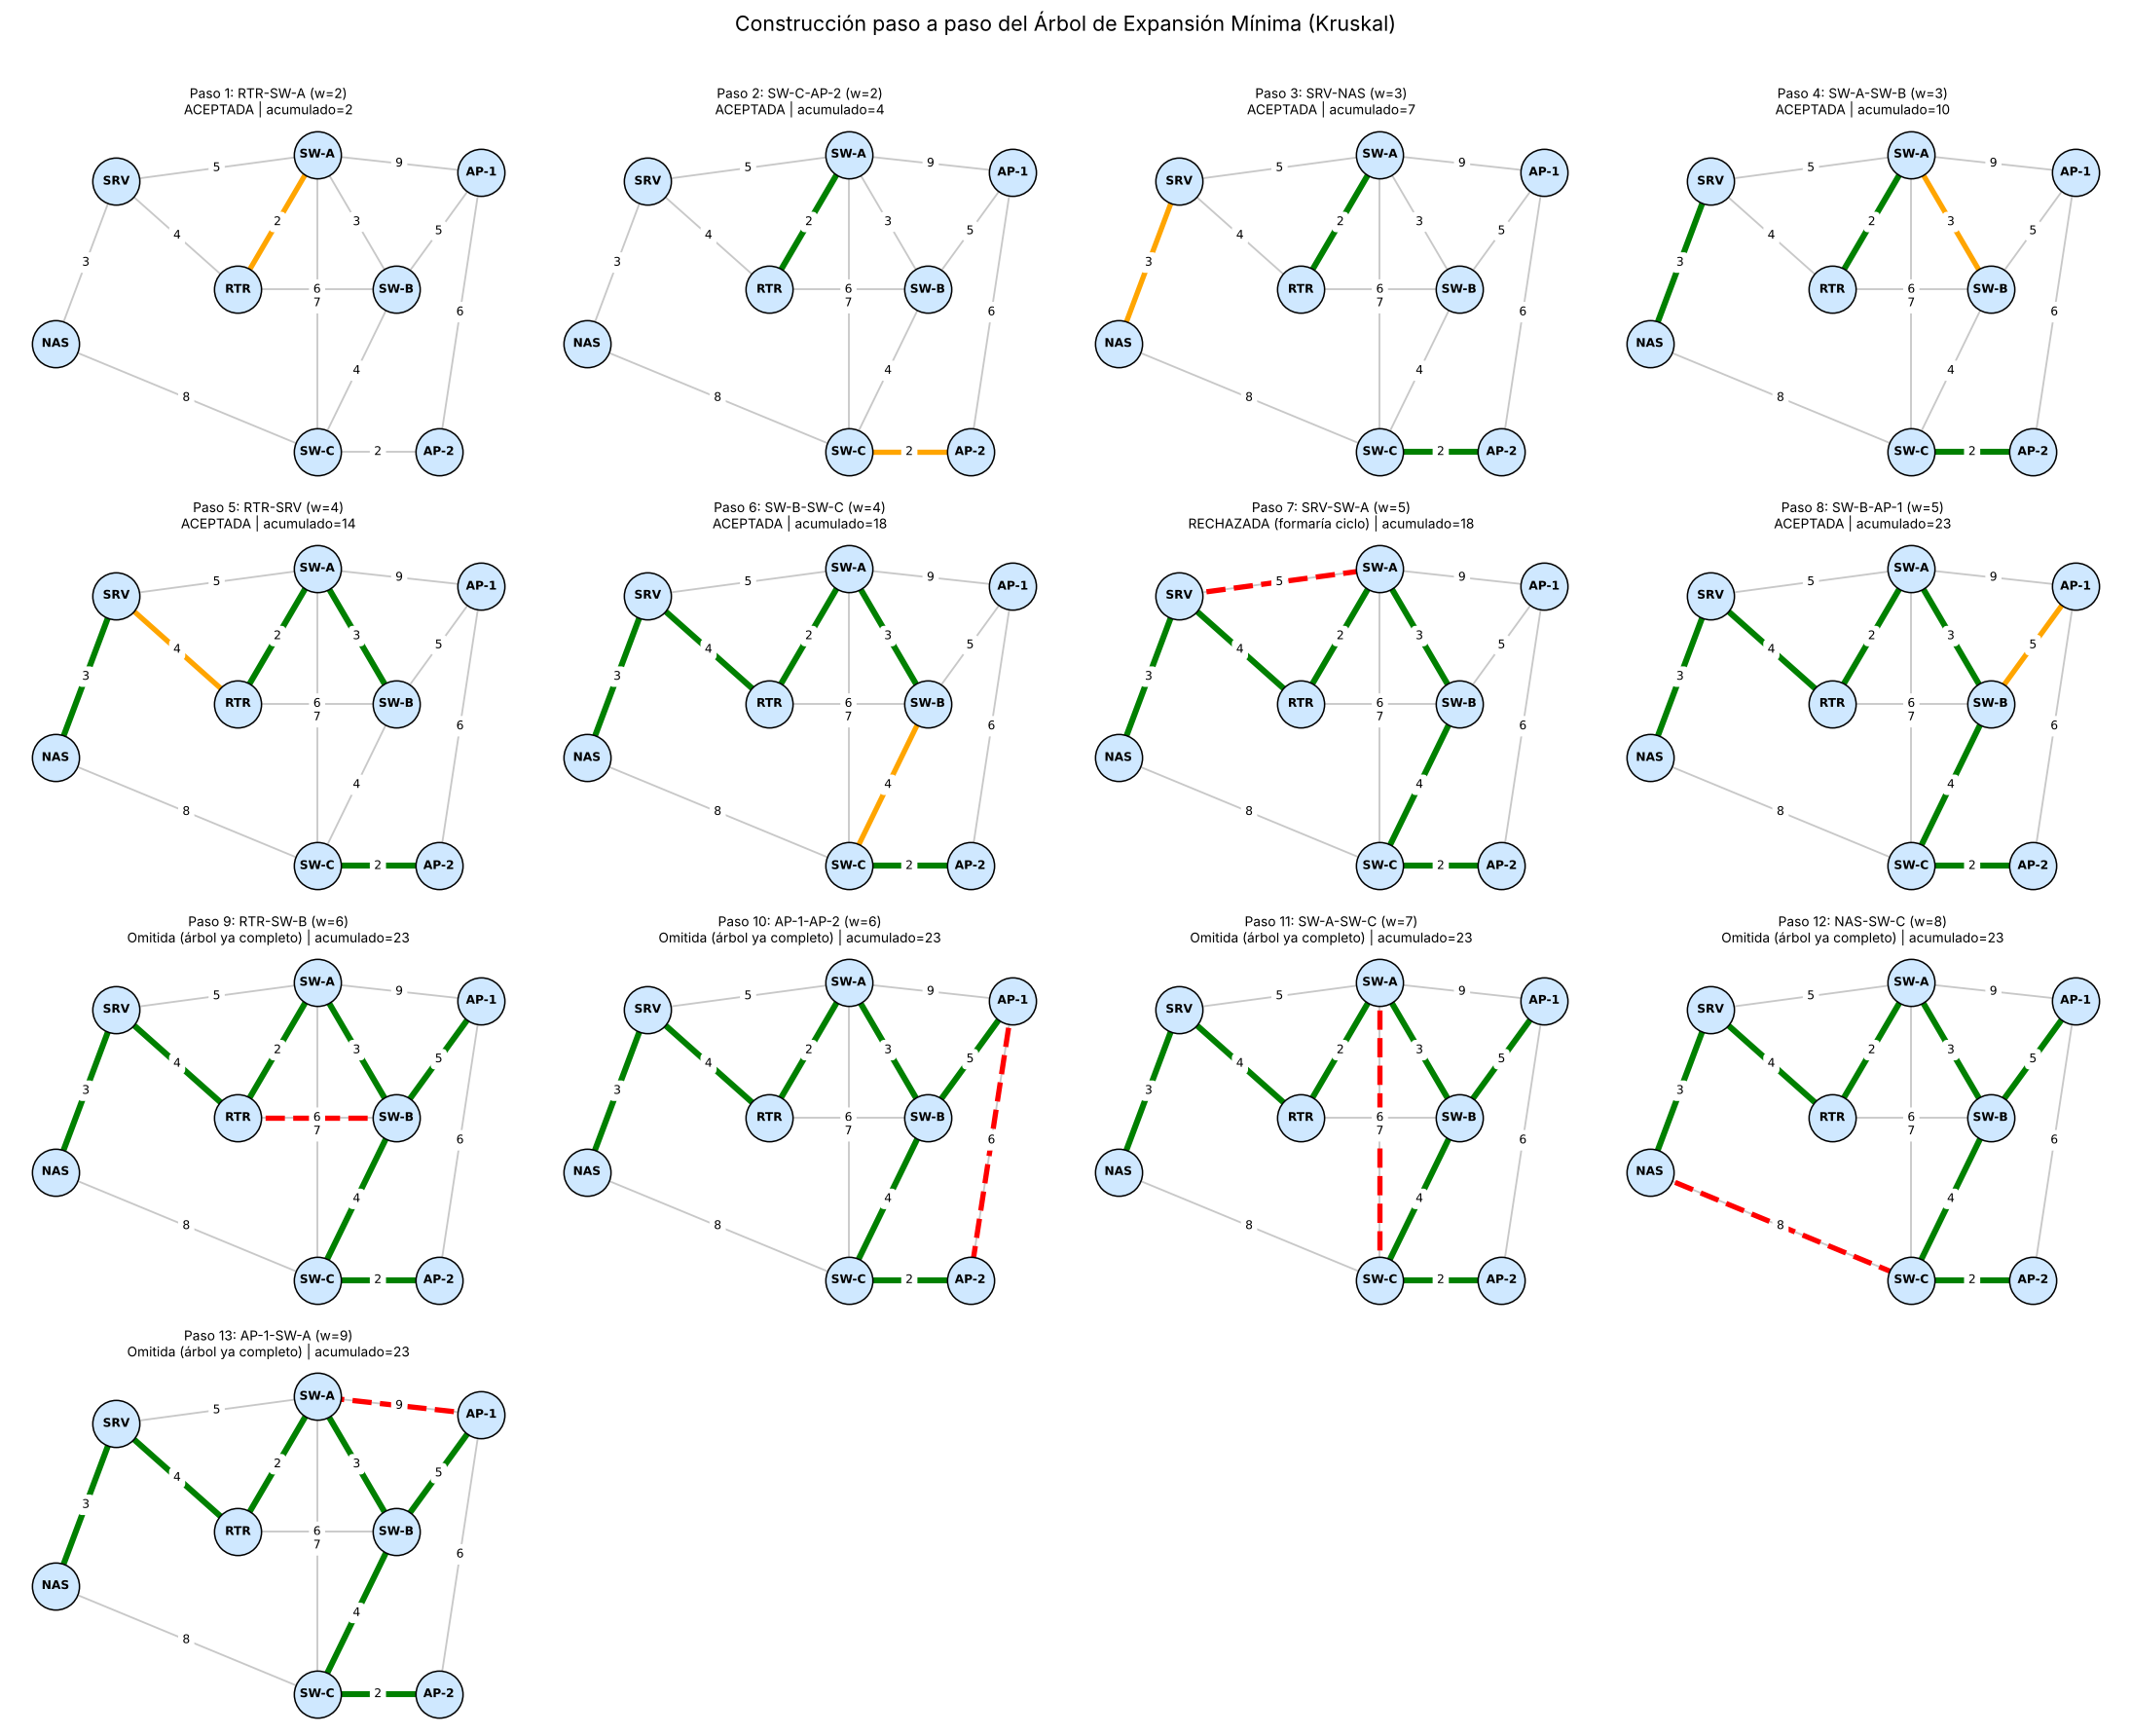

In [7]:
n = len(pasos)
cols = 4
filas = math.ceil(n / cols)
fig, axes = plt.subplots(filas, cols, figsize=(5 * cols, 4 * filas))
axes = axes.flatten()

for k, (arista, w, acept, rech, acumulado, decision) in enumerate(pasos):
    # Las aristas aceptadas "antes" de este paso (sin la actual, para resaltarla aparte)
    previas = [e for e in acept if set(e) != set(arista)] if not rech else acept
    titulo = f"Paso {k+1}: {arista[0]}-{arista[1]} (w={w})\n{decision} | acumulado={acumulado}"
    dibujar_mst(axes[k], G1, pos1, aceptadas=previas, evaluada=arista, rechazada=rech, titulo=titulo)

for j in range(n, len(axes)):
    axes[j].axis("off")
plt.suptitle("Construcción paso a paso del Árbol de Expansión Mínima (Kruskal)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Evolución del costo acumulado
Muestra cómo crece el costo conforme Kruskal agrega aristas. Solo cambia en los pasos aceptados.

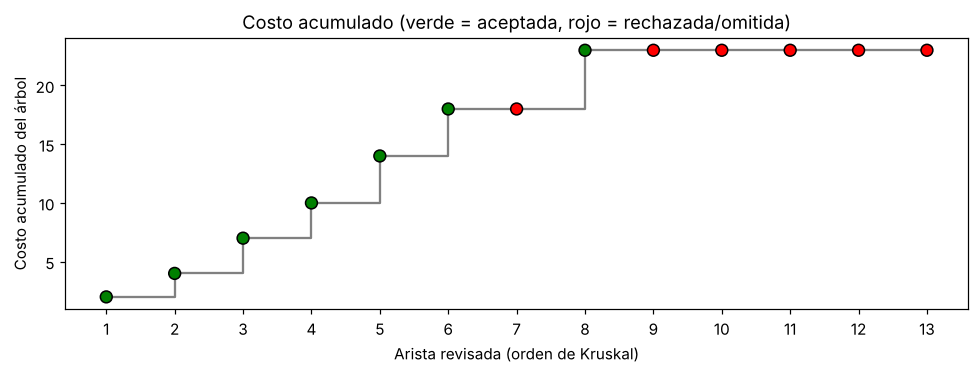

In [8]:
acum = [p[4] for p in pasos]
colores = ["green" if not p[3] else "red" for p in pasos]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.step(range(1, len(acum) + 1), acum, where="post", color="gray")
ax.scatter(range(1, len(acum) + 1), acum, c=colores, zorder=3, s=60, edgecolor="black")
ax.set_xlabel("Arista revisada (orden de Kruskal)")
ax.set_ylabel("Costo acumulado del árbol")
ax.set_title("Costo acumulado (verde = aceptada, rojo = rechazada/omitida)")
ax.set_xticks(range(1, len(acum) + 1))
plt.tight_layout()
plt.show()

## 1.7 Resultado final y verificación
Se compara la solución propia con la función `nx.minimum_spanning_tree` de NetworkX para **validar** que la implementación es correcta.

Aristas del MST (implementación propia):


,Origen,Destino,Costo
0,RTR,SW-A,2
1,SW-C,AP-2,2
2,SRV,NAS,3
3,SW-A,SW-B,3
4,RTR,SRV,4
5,SW-B,SW-C,4
6,SW-B,AP-1,5


Costo total (propio):   23
Costo total (NetworkX): 23
¿Coinciden? True


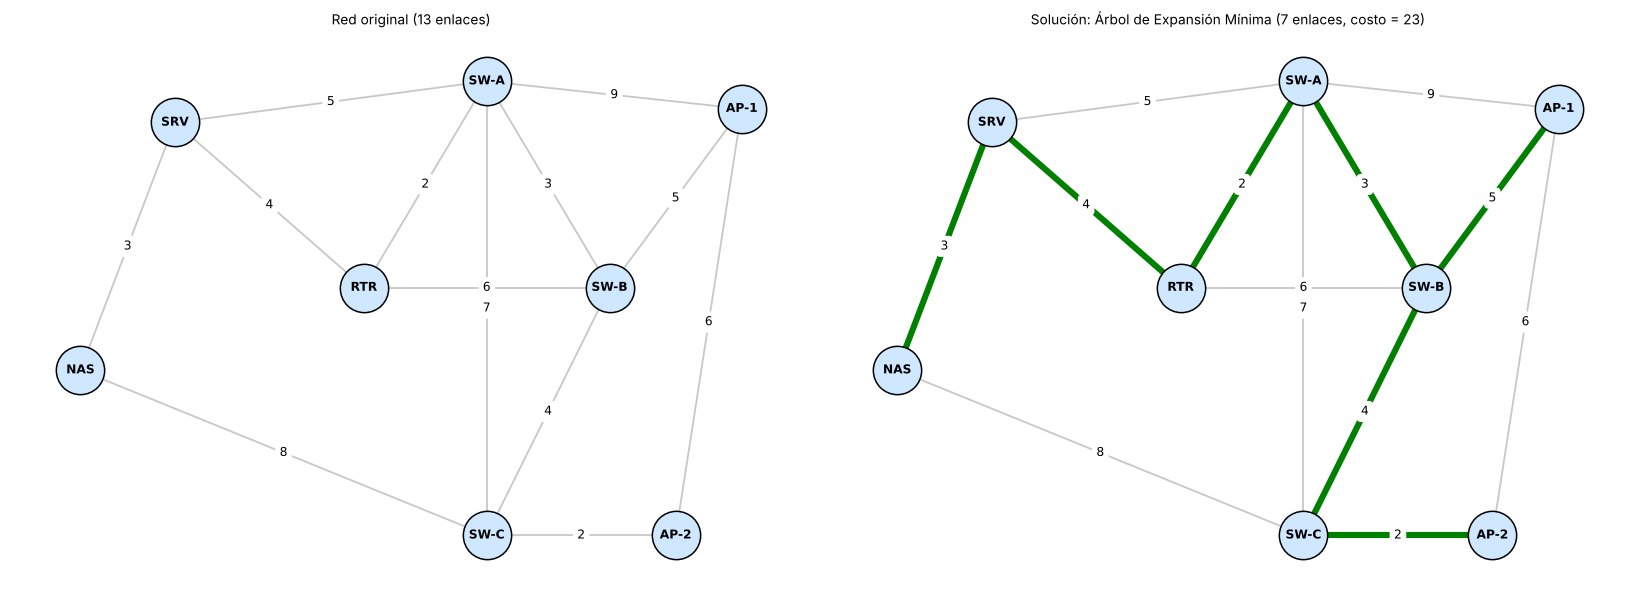

In [9]:
T_nx = nx.minimum_spanning_tree(G1, algorithm="kruskal")
costo_nx = T_nx.size(weight="weight")

print("Aristas del MST (implementación propia):")
df_mst = pd.DataFrame([(u, v, G1[u][v]["weight"]) for u, v in mst_aristas],
                      columns=["Origen", "Destino", "Costo"])
display(df_mst)
print(f"Costo total (propio):   {costo_total}")
print(f"Costo total (NetworkX): {costo_nx:g}")
print("¿Coinciden?", math.isclose(costo_total, costo_nx))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
dibujar_mst(axes[0], G1, pos1, titulo=f"Red original (13 enlaces)")
dibujar_mst(axes[1], G1, pos1, aceptadas=mst_aristas,
            titulo=f"Solución: Árbol de Expansión Mínima (7 enlaces, costo = {costo_total})")
plt.tight_layout()
plt.show()

## 1.8 Interpretación de resultados y aplicación al área de TI

- El **costo mínimo total es 23** (2 300 pesos en el modelo): con solo **7 de los 13 enlaces** se conectan los 8 dispositivos.
- Los enlaces descartados (`SRV-SW-A`, `RTR-SW-B`, `AP-1-AP-2`, `SW-A-SW-C`, `NAS-SW-C`, `AP-1-SW-A`) habrían creado **ciclos** y, por tanto, cableado redundante.
- El árbol resultante no tiene tolerancia a fallos: si un cable se corta, la red se divide. En una instalación real se podrían agregar enlaces extra *a propósito* para dar redundancia, sabiendo cuánto cuesta cada uno sobre el mínimo.
- **Aplicaciones en TI:** diseño de topologías de red de costo mínimo, el protocolo **Spanning Tree (STP)** que evita bucles en switches Ethernet, planeación de enlaces de fibra óptica entre sucursales, y agrupamiento jerárquico (*clustering*) en ciencia de datos.

<a id="practica2"></a>
---
# PRÁCTICA 2. Ruta Crítica (PERT/CPM)

## 2.1 Título del problema
**Planeación del desarrollo e implantación de un sistema web.**

## 2.2 Descripción y planteamiento
Un equipo de TI debe desarrollar y poner en producción un sistema web. El proyecto se divide en **11 actividades** con duraciones (en días) y relaciones de precedencia conocidas.

**Objetivo:** determinar la **duración mínima del proyecto**, qué actividades no pueden retrasarse (**ruta crítica**) y cuánto margen (**holgura**) tienen las demás.

## 2.3 Formulación matemática
Para cada actividad $i$ con duración $d_i$ y predecesoras $P(i)$:

**Pasada hacia adelante** (tiempos tempranos):
$$ES_i=\max_{j\in P(i)} EF_j \quad(\text{0 si no tiene predecesoras}),\qquad EF_i=ES_i+d_i$$

**Duración del proyecto:** $D=\max_i EF_i$

**Pasada hacia atrás** (tiempos tardíos), con $S(i)$ el conjunto de sucesoras:
$$LF_i=\min_{j\in S(i)} LS_j \quad(D \text{ si no tiene sucesoras}),\qquad LS_i=LF_i-d_i$$

**Holgura total:** $H_i=LS_i-ES_i=LF_i-EF_i$  
Una actividad es **crítica** si $H_i=0$. La ruta crítica es la cadena de actividades críticas de inicio a fin.

## 2.4 Definición de datos
Se define cada actividad con su descripción, duración y predecesoras. El proyecto se modela como un **grafo dirigido acíclico (DAG)**: los nodos son actividades y las flechas son precedencias.

In [10]:
actividades = {
    # id: (descripción, duración en días, [predecesoras])
    "A": ("Análisis de requisitos",        3, []),
    "B": ("Diseño de base de datos",       4, ["A"]),
    "C": ("Diseño de interfaz (UI/UX)",    3, ["A"]),
    "D": ("Configurar servidor y entorno", 2, ["A"]),
    "E": ("Desarrollo del backend",        6, ["B", "D"]),
    "F": ("Desarrollo del frontend",       5, ["C"]),
    "G": ("Integración backend-frontend",  3, ["E", "F"]),
    "H": ("Pruebas de integración",        4, ["G"]),
    "I": ("Documentación técnica",         3, ["E", "F"]),
    "J": ("Capacitación de usuarios",      2, ["H", "I"]),
    "K": ("Despliegue en producción",      1, ["J"]),
}

df_act = pd.DataFrame(
    [(k, d, dur, ", ".join(p) if p else "—") for k, (d, dur, p) in actividades.items()],
    columns=["Actividad", "Descripción", "Duración (días)", "Predecesoras"])
display(df_act)
print("Total de actividades:", len(actividades))
print("Suma de todas las duraciones:", sum(v[1] for v in actividades.values()), "días (si todo fuera secuencial)")

,Actividad,Descripción,Duración (días),Predecesoras
0,A,Análisis de requisitos,3,—
1,B,Diseño de base de datos,4,A
2,C,Diseño de interfaz (UI/UX),3,A
3,D,Configurar servidor y entorno,2,A
4,E,Desarrollo del backend,6,"B, D"
5,F,Desarrollo del frontend,5,C
6,G,Integración backend-frontend,3,"E, F"
7,H,Pruebas de integración,4,G
8,I,Documentación técnica,3,"E, F"
9,J,Capacitación de usuarios,2,"H, I"


Total de actividades: 11
Suma de todas las duraciones: 36 días (si todo fuera secuencial)


### Construcción del grafo de precedencias
Se crea el DAG y se verifica que no tenga ciclos (un proyecto con precedencias circulares sería imposible de ejecutar). Los nodos se acomodan por "niveles" para que el flujo se lea de izquierda a derecha.

In [11]:
G2 = nx.DiGraph()
for k, (desc, dur, preds) in actividades.items():
    G2.add_node(k, dur=dur, desc=desc)
    for p in preds:
        G2.add_edge(p, k)

print("¿Es un DAG (sin ciclos)?", nx.is_directed_acyclic_graph(G2))
niveles = list(nx.topological_generations(G2))
for i, nivel in enumerate(niveles):
    print(f"Nivel {i}: {nivel}")
    for nodo in nivel:
        G2.nodes[nodo]["nivel"] = i

pos2 = nx.multipartite_layout(G2, subset_key="nivel")
# Ajuste manual para separar mejor los nodos verticalmente
for nivel in niveles:
    n_ = len(nivel)
    for j, nodo in enumerate(sorted(nivel)):
        pos2[nodo] = (pos2[nodo][0] * 1.0, (n_ - 1) / 2 - j)

¿Es un DAG (sin ciclos)? True
Nivel 0: ['A']
Nivel 1: ['B', 'C', 'D']
Nivel 2: ['F', 'E']
Nivel 3: ['G', 'I']
Nivel 4: ['H']
Nivel 5: ['J']
Nivel 6: ['K']


### Función auxiliar de dibujo
Cada nodo es una caja con la letra de la actividad, su duración y (cuando existan) sus tiempos. Las flechas y cajas **críticas** se pintan en rojo.

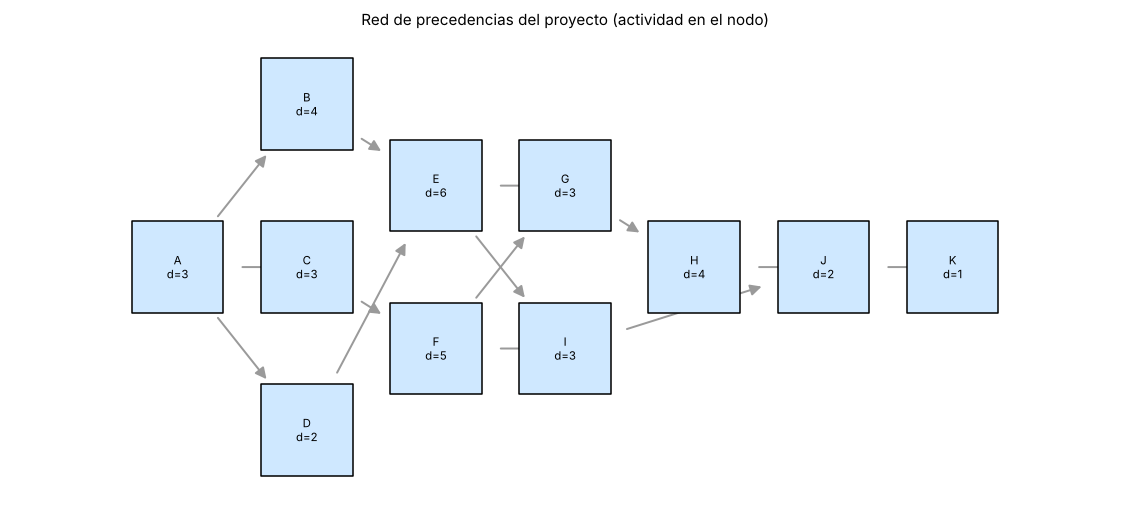

In [12]:
def dibujar_cpm(ax, texto_nodo, titulo, criticos=(), visibles=None):
    nodos = list(G2.nodes()) if visibles is None else list(visibles)
    sub = G2.subgraph(nodos)
    colores = ["#ff9b9b" if n in criticos else "#cfe8ff" for n in sub.nodes()]
    nx.draw_networkx_nodes(sub, pos2, ax=ax, node_shape="s", node_size=3600,
                           node_color=colores, edgecolors="black")
    nx.draw_networkx_edges(G2, pos2, ax=ax, node_shape="s", node_size=3600, arrowsize=15,
                           edge_color="#9a9a9a", width=1.3)
    if criticos:
        aristas_crit = [(u, v) for u, v in G2.edges() if u in criticos and v in criticos]
        nx.draw_networkx_edges(G2, pos2, edgelist=aristas_crit, ax=ax, node_shape="s", node_size=3600,
                               arrowsize=18, edge_color="red", width=3)
    for n in sub.nodes():
        x, y = pos2[n]
        ax.text(x, y, texto_nodo(n), ha="center", va="center", fontsize=7.5)
    ax.set_title(titulo, fontsize=10)
    ax.margins(0.15)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(13, 5.5))
dibujar_cpm(ax, lambda n: f"{n}\nd={G2.nodes[n]['dur']}", "Red de precedencias del proyecto (actividad en el nodo)")
plt.show()

## 2.5 Desarrollo del algoritmo

### Paso 1. Pasada hacia adelante (ES y EF)
Se recorren las actividades en **orden topológico** (siempre después de sus predecesoras). Se imprime cada cálculo para ver cómo se construyen los tiempos.

In [13]:
orden = list(nx.topological_sort(G2))
ES, EF = {}, {}

print("PASADA HACIA ADELANTE")
print("-" * 70)
for a in orden:
    preds = actividades[a][2]
    dur = actividades[a][1]
    if preds:
        ES[a] = max(EF[p] for p in preds)
        detalle = f"ES = max({', '.join(f'EF_{p}={EF[p]}' for p in preds)}) = {ES[a]}"
    else:
        ES[a] = 0
        detalle = "ES = 0 (sin predecesoras)"
    EF[a] = ES[a] + dur
    print(f"Actividad {a}: {detalle:<38} | EF = {ES[a]} + {dur} = {EF[a]}")

D = max(EF.values())
print("-" * 70)
print(f"DURACIÓN TOTAL DEL PROYECTO = max(EF) = {D} días")

PASADA HACIA ADELANTE
----------------------------------------------------------------------
Actividad A: ES = 0 (sin predecesoras)              | EF = 0 + 3 = 3
Actividad B: ES = max(EF_A=3) = 3                   | EF = 3 + 4 = 7
Actividad C: ES = max(EF_A=3) = 3                   | EF = 3 + 3 = 6
Actividad D: ES = max(EF_A=3) = 3                   | EF = 3 + 2 = 5
Actividad F: ES = max(EF_C=6) = 6                   | EF = 6 + 5 = 11
Actividad E: ES = max(EF_B=7, EF_D=5) = 7           | EF = 7 + 6 = 13
Actividad G: ES = max(EF_E=13, EF_F=11) = 13        | EF = 13 + 3 = 16
Actividad I: ES = max(EF_E=13, EF_F=11) = 13        | EF = 13 + 3 = 16
Actividad H: ES = max(EF_G=16) = 16                 | EF = 16 + 4 = 20
Actividad J: ES = max(EF_H=20, EF_I=16) = 20        | EF = 20 + 2 = 22
Actividad K: ES = max(EF_J=22) = 22                 | EF = 22 + 1 = 23
----------------------------------------------------------------------
DURACIÓN TOTAL DEL PROYECTO = max(EF) = 23 días


**Visualización de la pasada hacia adelante.** Cada recuadro agrega un nivel más de actividades con su `ES | EF`.

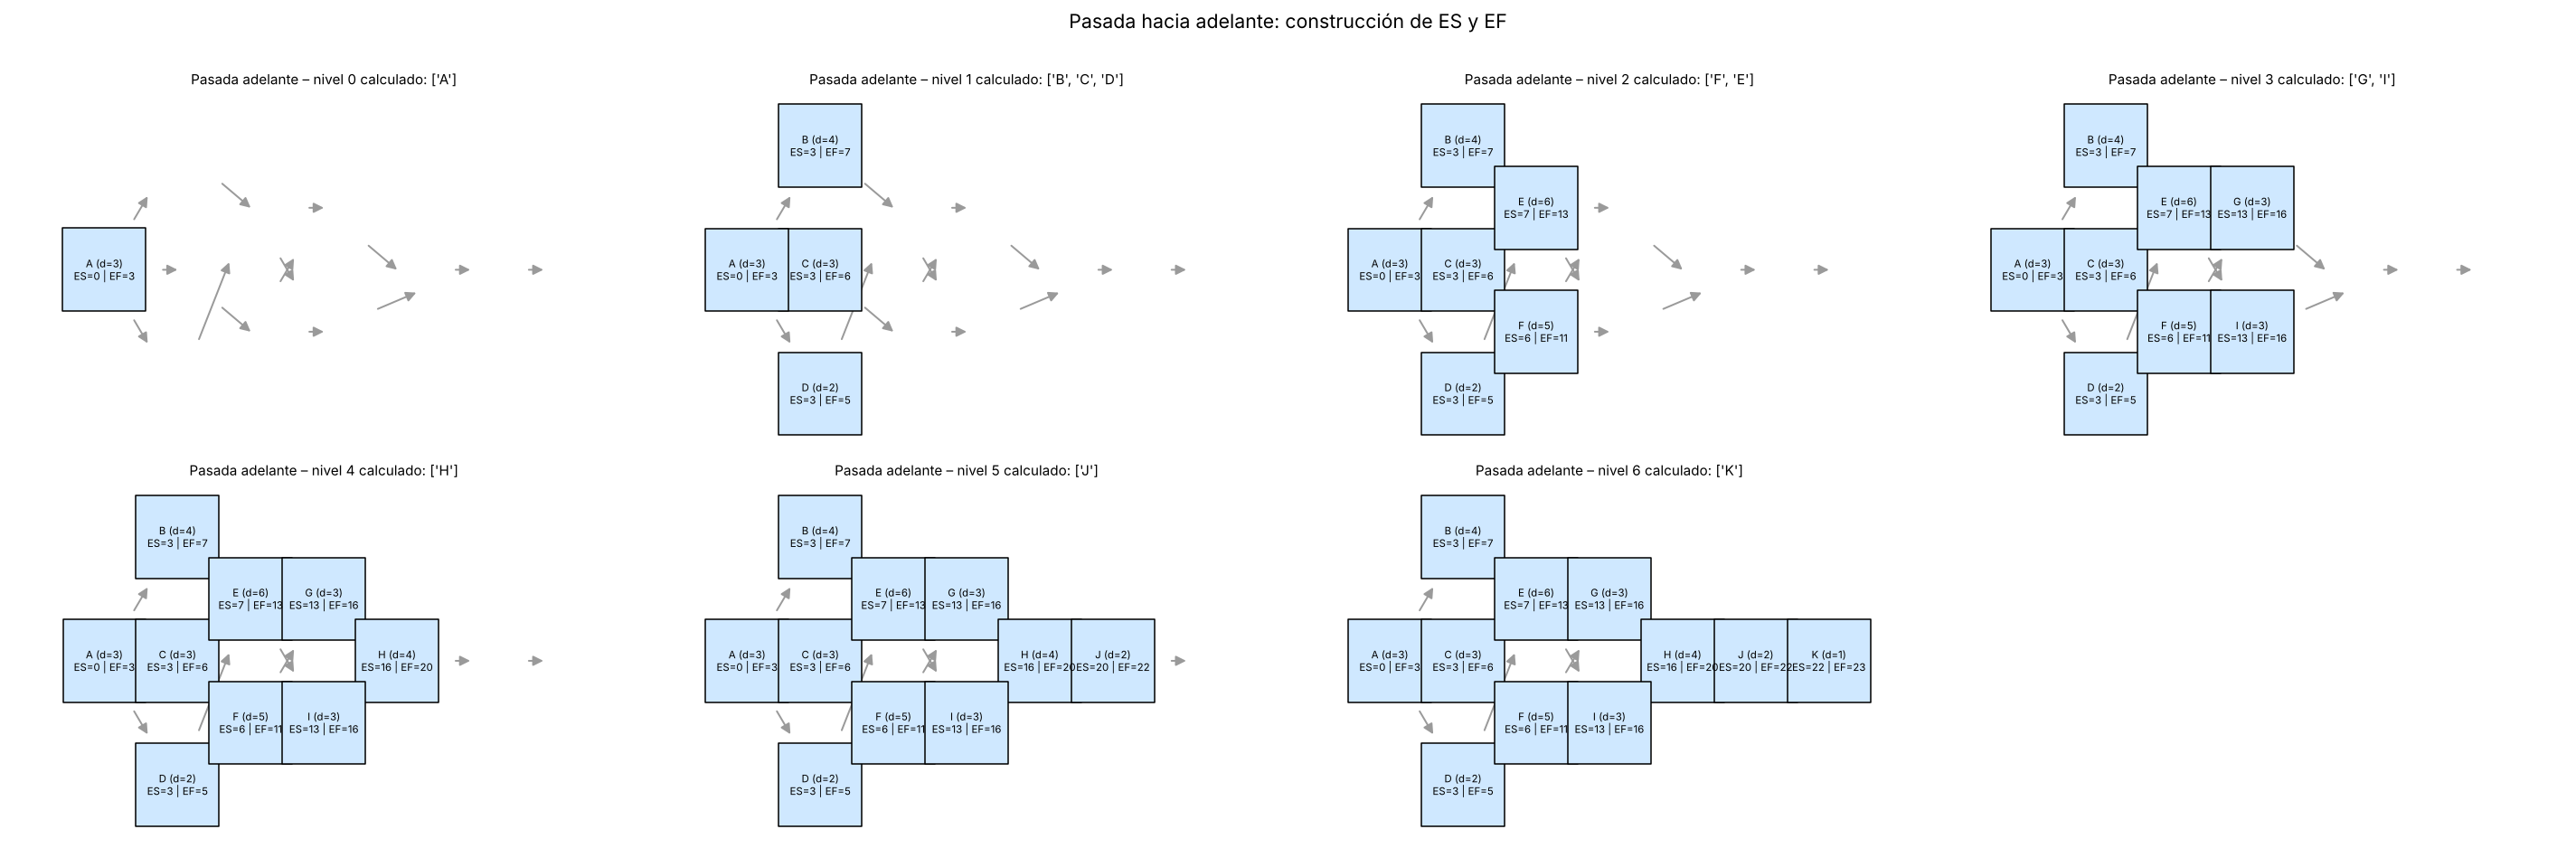

In [14]:
n = len(niveles)
cols = 4
filas = math.ceil(n / cols)
fig, axes = plt.subplots(filas, cols, figsize=(6.5 * cols, 4.2 * filas))
axes = axes.flatten()
acumulados = []
for i, nivel in enumerate(niveles):
    acumulados += nivel
    vis = list(acumulados)
    txt = lambda nd, vis=vis: f"{nd} (d={G2.nodes[nd]['dur']})\nES={ES[nd]} | EF={EF[nd]}"
    dibujar_cpm(axes[i], txt, f"Pasada adelante – nivel {i} calculado: {nivel}", visibles=vis)
for j in range(n, len(axes)):
    axes[j].axis("off")
plt.suptitle("Pasada hacia adelante: construcción de ES y EF", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Paso 2. Pasada hacia atrás (LS y LF)
Se recorren las actividades en **orden inverso**. Las actividades finales terminan, como máximo, en la duración total $D$.

In [15]:
LS, LF = {}, {}
sucesoras = {a: list(G2.successors(a)) for a in G2.nodes()}

print("PASADA HACIA ATRÁS")
print("-" * 70)
for a in reversed(orden):
    dur = actividades[a][1]
    suc = sucesoras[a]
    if suc:
        LF[a] = min(LS[s] for s in suc)
        detalle = f"LF = min({', '.join(f'LS_{s}={LS[s]}' for s in suc)}) = {LF[a]}"
    else:
        LF[a] = D
        detalle = f"LF = D = {D} (sin sucesoras)"
    LS[a] = LF[a] - dur
    print(f"Actividad {a}: {detalle:<38} | LS = {LF[a]} - {dur} = {LS[a]}")

PASADA HACIA ATRÁS
----------------------------------------------------------------------
Actividad K: LF = D = 23 (sin sucesoras)            | LS = 23 - 1 = 22
Actividad J: LF = min(LS_K=22) = 22                 | LS = 22 - 2 = 20
Actividad H: LF = min(LS_J=20) = 20                 | LS = 20 - 4 = 16
Actividad I: LF = min(LS_J=20) = 20                 | LS = 20 - 3 = 17
Actividad G: LF = min(LS_H=16) = 16                 | LS = 16 - 3 = 13
Actividad E: LF = min(LS_G=13, LS_I=17) = 13        | LS = 13 - 6 = 7
Actividad F: LF = min(LS_G=13, LS_I=17) = 13        | LS = 13 - 5 = 8
Actividad D: LF = min(LS_E=7) = 7                   | LS = 7 - 2 = 5
Actividad C: LF = min(LS_F=8) = 8                   | LS = 8 - 3 = 5
Actividad B: LF = min(LS_E=7) = 7                   | LS = 7 - 4 = 3
Actividad A: LF = min(LS_B=3, LS_C=5, LS_D=5) = 3   | LS = 3 - 3 = 0


**Visualización de la pasada hacia atrás.** Ahora se recorre el grafo desde el final; cada recuadro muestra un nivel más con `LS | LF`.

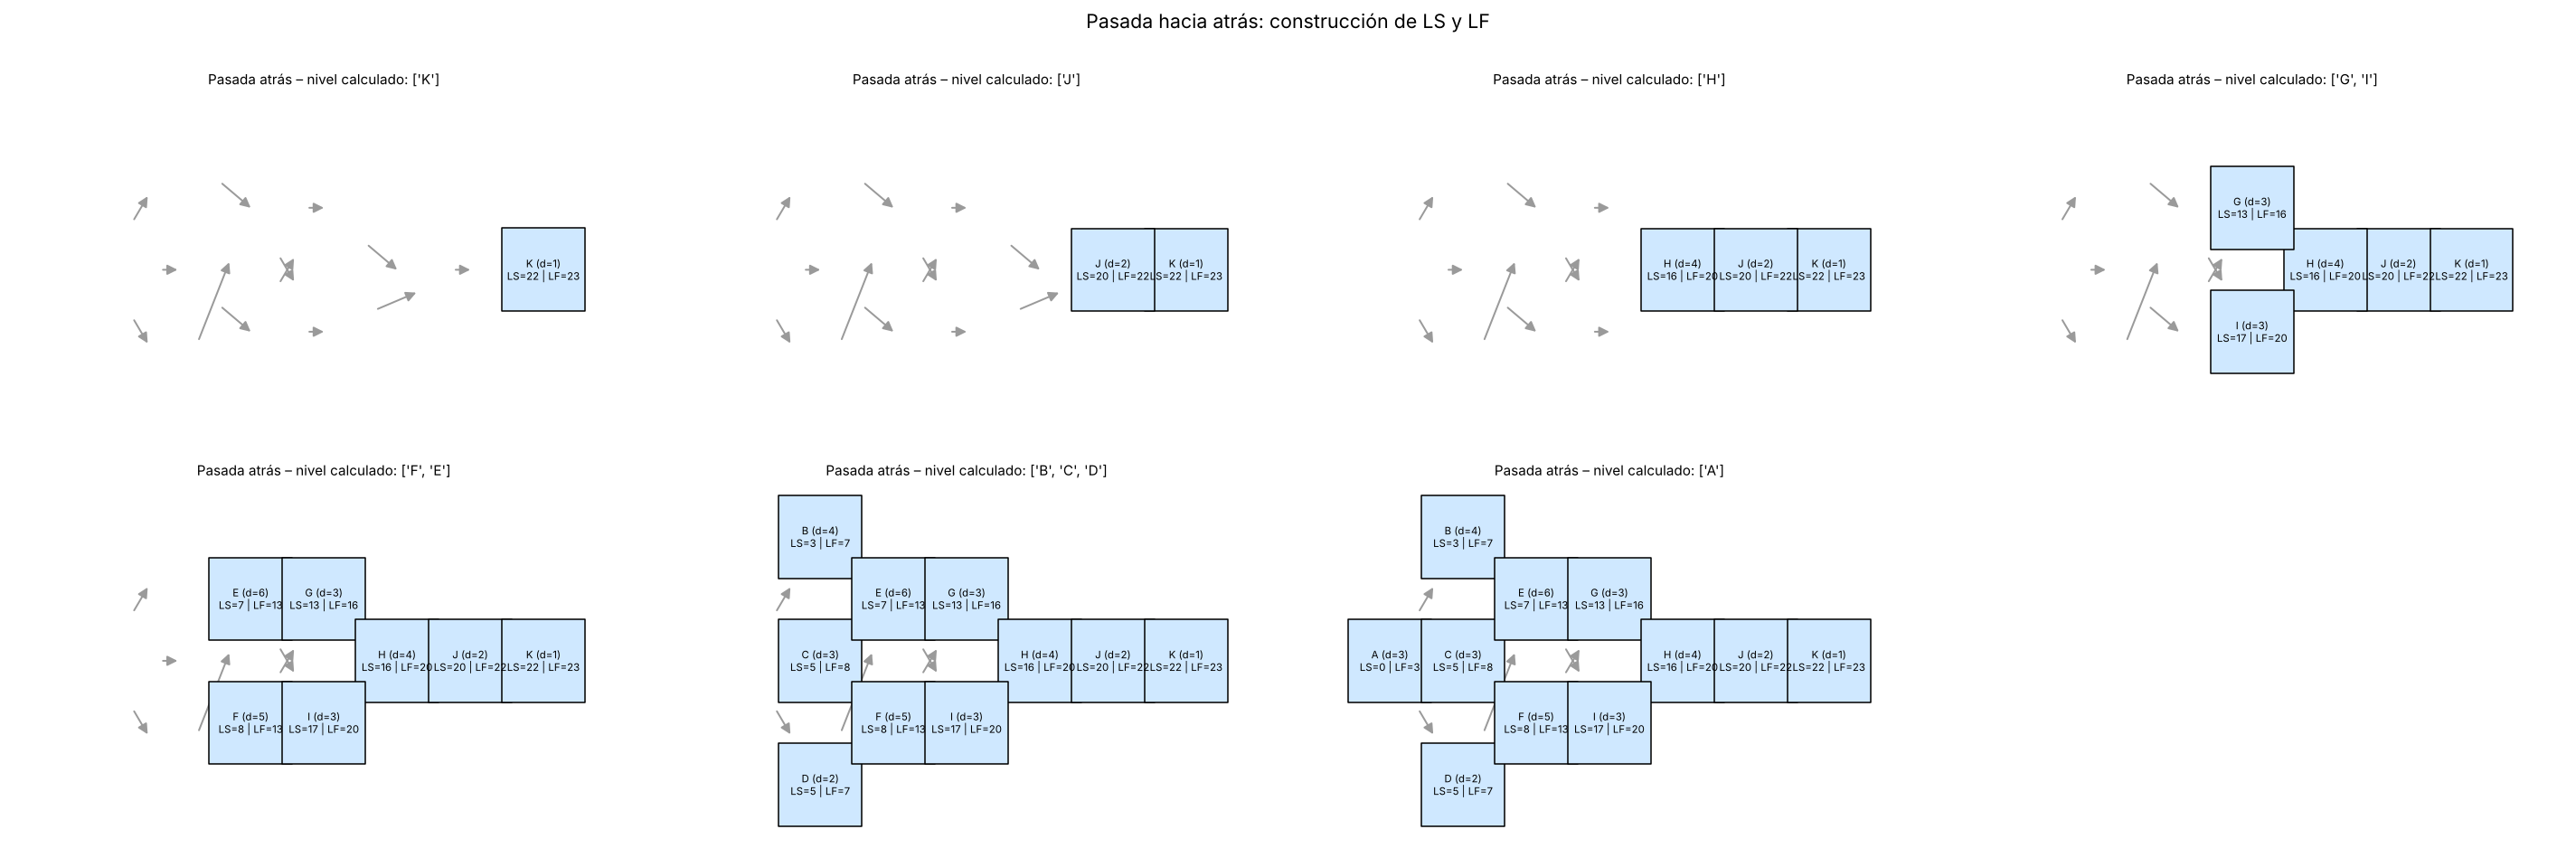

In [16]:
fig, axes = plt.subplots(filas, cols, figsize=(6.5 * cols, 4.2 * filas))
axes = axes.flatten()
acumulados = []
for i, nivel in enumerate(reversed(niveles)):
    acumulados += nivel
    vis = list(acumulados)
    txt = lambda nd: f"{nd} (d={G2.nodes[nd]['dur']})\nLS={LS[nd]} | LF={LF[nd]}"
    dibujar_cpm(axes[i], txt, f"Pasada atrás – nivel calculado: {nivel}", visibles=vis)
for j in range(n, len(axes)):
    axes[j].axis("off")
plt.suptitle("Pasada hacia atrás: construcción de LS y LF", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Paso 3. Holguras y ruta crítica
La holgura $H=LS-ES$ indica cuántos días puede retrasarse una actividad **sin** retrasar el proyecto. Si $H=0$, la actividad es crítica.

In [17]:
holgura = {a: LS[a] - ES[a] for a in orden}
criticas = [a for a in orden if holgura[a] == 0]

tabla = pd.DataFrame({
    "Actividad":   orden,
    "Descripción": [actividades[a][0] for a in orden],
    "Duración":    [actividades[a][1] for a in orden],
    "ES": [ES[a] for a in orden], "EF": [EF[a] for a in orden],
    "LS": [LS[a] for a in orden], "LF": [LF[a] for a in orden],
    "Holgura": [holgura[a] for a in orden],
    "¿Crítica?": ["SÍ" if holgura[a] == 0 else "no" for a in orden],
})

def resaltar(fila):
    return ["background-color: #ffb3b3" if fila["¿Crítica?"] == "SÍ" else "" for _ in fila]

display(tabla.style.apply(resaltar, axis=1).hide(axis="index"))

print("Actividades críticas:", criticas)
print("Ruta crítica:", " → ".join(criticas))
print("Suma de duraciones críticas:", sum(actividades[a][1] for a in criticas), "días")
print("Duración total del proyecto:", D, "días")

Actividad,Descripción,Duración,ES,EF,LS,LF,Holgura,¿Crítica?
A,Análisis de requisitos,3,0,3,0,3,0,SÍ
B,Diseño de base de datos,4,3,7,3,7,0,SÍ
C,Diseño de interfaz (UI/UX),3,3,6,5,8,2,no
D,Configurar servidor y entorno,2,3,5,5,7,2,no
F,Desarrollo del frontend,5,6,11,8,13,2,no
E,Desarrollo del backend,6,7,13,7,13,0,SÍ
G,Integración backend-frontend,3,13,16,13,16,0,SÍ
I,Documentación técnica,3,13,16,17,20,4,no
H,Pruebas de integración,4,16,20,16,20,0,SÍ
J,Capacitación de usuarios,2,20,22,20,22,0,SÍ


Actividades críticas: ['A', 'B', 'E', 'G', 'H', 'J', 'K']
Ruta crítica: A → B → E → G → H → J → K
Suma de duraciones críticas: 23 días
Duración total del proyecto: 23 días


## 2.6 Visualización de resultados
### Red con la ruta crítica resaltada
Las cajas y flechas rojas forman la ruta crítica; cada caja muestra los cuatro tiempos y la holgura.

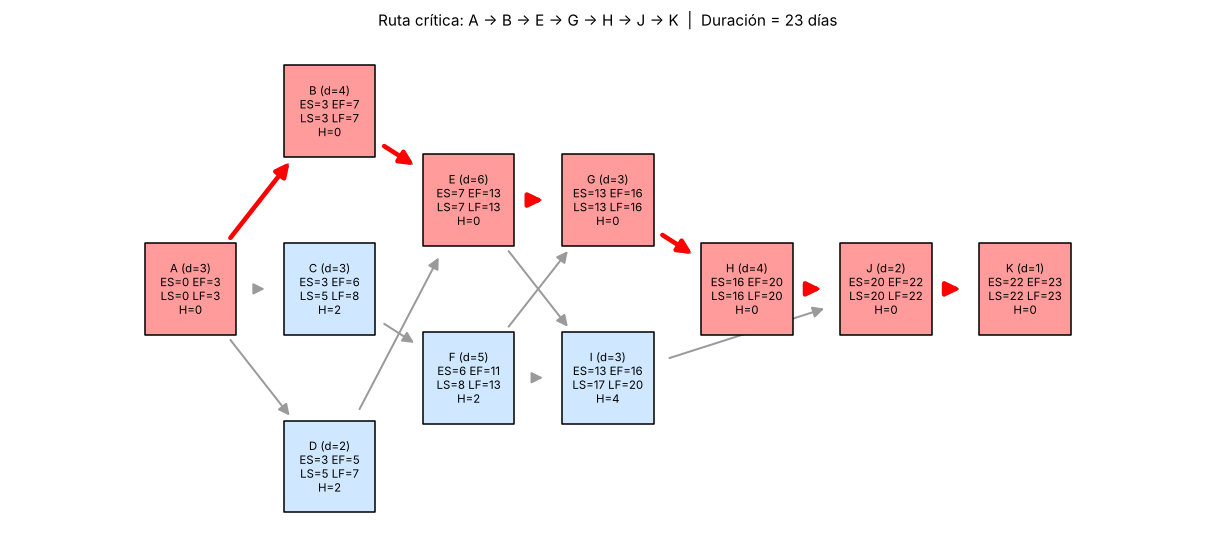

In [18]:
fig, ax = plt.subplots(figsize=(14, 6))
txt = lambda nd: (f"{nd} (d={G2.nodes[nd]['dur']})\nES={ES[nd]} EF={EF[nd]}\n"
                  f"LS={LS[nd]} LF={LF[nd]}\nH={holgura[nd]}")
dibujar_cpm(ax, txt, f"Ruta crítica: {' → '.join(criticas)}  |  Duración = {D} días", criticos=criticas)
plt.show()

### Diagrama de Gantt
Las barras rojas son actividades críticas. Las barras azules claras tienen **holgura**: la zona rayada muestra cuántos días se pueden retrasar sin afectar el proyecto.

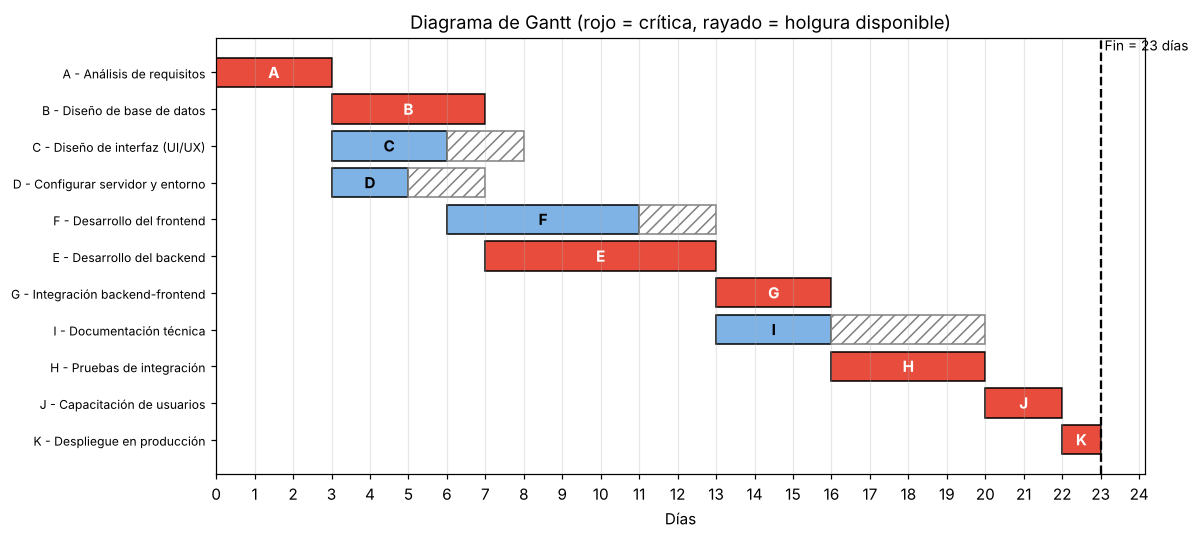

In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
orden_gantt = sorted(orden, key=lambda a: (ES[a], a), reverse=True)
for i, a in enumerate(orden_gantt):
    crit = holgura[a] == 0
    ax.barh(i, actividades[a][1], left=ES[a], color="#e74c3c" if crit else "#7fb3e6", edgecolor="black")
    if holgura[a] > 0:
        ax.barh(i, holgura[a], left=EF[a], color="none", edgecolor="gray", hatch="///")
    ax.text(ES[a] + actividades[a][1] / 2, i, a, ha="center", va="center", color="white" if crit else "black", fontweight="bold")
ax.set_yticks(range(len(orden_gantt)))
ax.set_yticklabels([f"{a} - {actividades[a][0]}" for a in orden_gantt], fontsize=8)
ax.axvline(D, color="black", linestyle="--")
ax.text(D, len(orden_gantt) - 0.4, f" Fin = {D} días", fontsize=9)
ax.set_xlabel("Días")
ax.set_xticks(range(0, D + 2))
ax.set_title("Diagrama de Gantt (rojo = crítica, rayado = holgura disponible)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Verificación con NetworkX
La ruta crítica es la **ruta más larga** del DAG ponderado por duraciones. Se verifica con `nx.dag_longest_path`.

In [20]:
# Para usar duraciones en los nodos se pasan a las aristas (peso = duración del nodo origen)
H = nx.DiGraph()
for u, v in G2.edges():
    H.add_edge(u, v, weight=actividades[u][1])
ruta_nx = nx.dag_longest_path(H, weight="weight")
largo_nx = nx.dag_longest_path_length(H, weight="weight") + actividades[ruta_nx[-1]][1]
print("Ruta más larga (NetworkX):", " → ".join(ruta_nx))
print("Duración (NetworkX):", largo_nx, "días")
print("¿Coincide con la ruta crítica calculada?", ruta_nx == criticas and largo_nx == D)

Ruta más larga (NetworkX): A → B → E → G → H → J → K
Duración (NetworkX): 23 días
¿Coincide con la ruta crítica calculada? True


## 2.7 Interpretación de resultados y aplicación al área de TI

- La **ruta crítica** es **A → B → E → G → H → J → K** y el proyecto dura **23 días**, a pesar de que la suma de todas las actividades sería 38 días: el trabajo en paralelo (por ejemplo, diseño de UI y configuración del servidor mientras se diseña la base de datos) ahorra 15 días.
- Cualquier retraso de un día en una actividad crítica **retrasa un día todo el proyecto**. Por eso el *backend* (E, 6 días) y las pruebas de integración (H) merecen la mayor atención del líder de proyecto.
- Las actividades **C, D, F** tienen 2 días de holgura y la **documentación (I)** tiene 4: pueden retrasarse sin consecuencias o servir de reserva para mover personal hacia las actividades críticas.
- **Aplicaciones en TI:** planeación de sprints y releases, cronogramas de migraciones de infraestructura, lanzamiento de productos de software, y herramientas como MS Project o Jira que usan CPM internamente. PERT agrega estimaciones probabilistas (optimista, probable, pesimista) cuando las duraciones son inciertas.

<a id="practica3"></a>
---
# PRÁCTICA 3. Algoritmo de Dijkstra

## 3.1 Título del problema
**Ruta de menor latencia entre dos routers de una red de campus.**

## 3.2 Descripción y planteamiento
Una red de campus tiene **9 routers** (`R1`…`R9`) interconectados por enlaces con una **latencia** medida en milisegundos. Se necesita encontrar el camino por el que un paquete viaja desde `R1` (origen) hasta `R9` (destino) con la **menor latencia total**.

## 3.3 Formulación matemática
Sea $G=(V,E)$ un grafo ponderado con pesos $w(u,v)\ge 0$. Para un origen $s$ se busca la distancia mínima $\delta(s,v)$ a cada nodo $v$:

$$\delta(s,v)=\min_{\text{caminos } P: s\to v}\ \sum_{(a,b)\in P} w(a,b)$$

**Algoritmo de Dijkstra:**
1. $d(s)=0$ y $d(v)=\infty$ para los demás nodos.
2. Seleccionar el nodo **no visitado** con menor $d$, marcarlo como visitado.
3. **Relajar** sus vecinos: si $d(u)+w(u,v)<d(v)$, entonces $d(v)\leftarrow d(u)+w(u,v)$ y se guarda $u$ como predecesor de $v$.
4. Repetir hasta visitar todos los nodos (o hasta llegar al destino).

Funciona porque los pesos no son negativos: al visitar un nodo, su distancia ya es definitiva.

## 3.4 Definición de datos

In [21]:
enlaces = [
    ("R1", "R2", 7),  ("R1", "R3", 9),  ("R1", "R6", 14),
    ("R2", "R3", 10), ("R2", "R4", 15), ("R3", "R4", 11),
    ("R3", "R6", 2),  ("R4", "R5", 6),  ("R4", "R8", 8),
    ("R5", "R6", 9),  ("R5", "R7", 3),  ("R7", "R8", 4),
    ("R8", "R9", 2),  ("R6", "R9", 20),
]
origen, destino = "R1", "R9"

G3 = nx.Graph()
G3.add_weighted_edges_from(enlaces)
pos3 = {"R1": (0, 0), "R2": (1.5, 2), "R3": (1.5, 0), "R6": (1.5, -2),
        "R4": (3.5, 2), "R5": (3.5, -1), "R7": (5.2, -1.6), "R8": (5.5, 1), "R9": (7, 0)}

print(f"Nodos: {G3.number_of_nodes()} | Enlaces: {G3.number_of_edges()}")
print(f"Origen: {origen} | Destino: {destino}")
display(pd.DataFrame(enlaces, columns=["Router A", "Router B", "Latencia (ms)"]))

Nodos: 9 | Enlaces: 14
Origen: R1 | Destino: R9


,Router A,Router B,Latencia (ms)
0,R1,R2,7
1,R1,R3,9
2,R1,R6,14
3,R2,R3,10
4,R2,R4,15
5,R3,R4,11
6,R3,R6,2
7,R4,R5,6
8,R4,R8,8
9,R5,R6,9


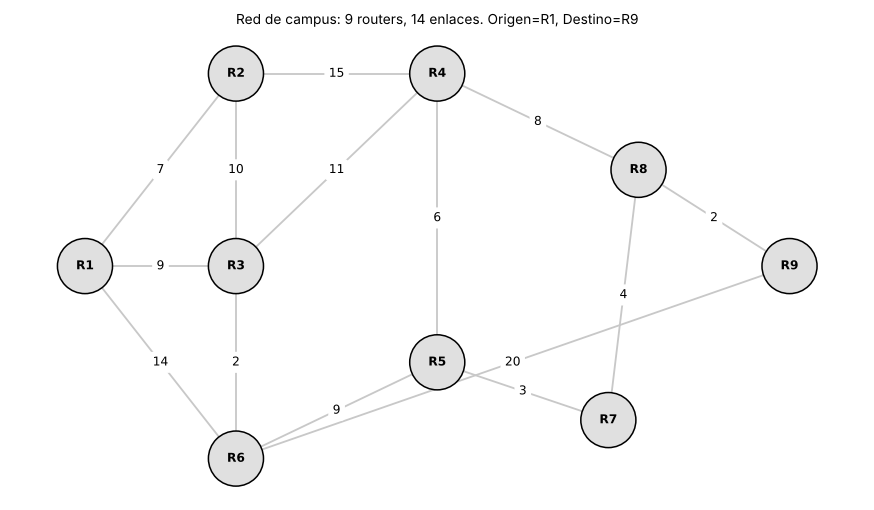

In [22]:
def dibujar_dij(ax, G, pos, dist=None, visitados=(), actual=None, arbol=(), camino=(), titulo=""):
    colores = []
    for n in G.nodes():
        if n == actual:                     colores.append("#ff9f43")   # nodo actual
        elif n in visitados:                colores.append("#8fd694")   # ya definitivo
        elif dist and dist[n] < math.inf:   colores.append("#fff3a3")   # frontera (distancia tentativa)
        else:                               colores.append("#e0e0e0")   # sin alcanzar aún
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colores, edgecolors="black", node_size=1300)
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c8c8c8", width=1.2)
    if arbol:
        nx.draw_networkx_edges(G, pos, edgelist=list(arbol), ax=ax, edge_color="#2e86de", width=3)
    if camino:
        nx.draw_networkx_edges(G, pos, edgelist=list(camino), ax=ax, edge_color="red", width=5)
    if dist:
        etiquetas = {n: f"{n}\n{'∞' if dist[n] == math.inf else dist[n]}" for n in G.nodes()}
    else:
        etiquetas = {n: n for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=etiquetas, ax=ax, font_size=8, font_weight="bold")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"),
                                 ax=ax, font_size=8, rotate=False)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(10, 5.5))
dibujar_dij(ax, G3, pos3, titulo=f"Red de campus: 9 routers, 14 enlaces. Origen={origen}, Destino={destino}")
plt.show()

## 3.5 Desarrollo del algoritmo

### Paso 1. Inicialización
$d(R1)=0$ y $d(v)=\infty$ para todos los demás; aún no hay predecesores ni nodos visitados.

Distancias iniciales: {'R1': 0, 'R2': '∞', 'R3': '∞', 'R6': '∞', 'R4': '∞', 'R5': '∞', 'R8': '∞', 'R7': '∞', 'R9': '∞'}
Cola de prioridad: [(0, 'R1')]


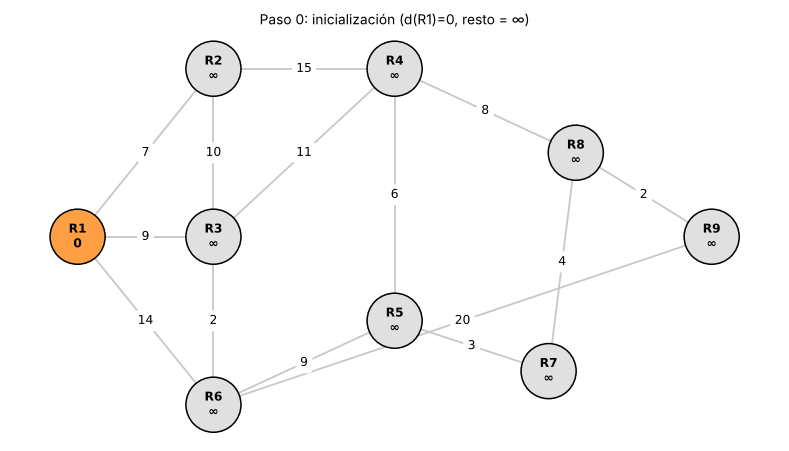

In [23]:
dist = {n: math.inf for n in G3.nodes()}
prev = {n: None for n in G3.nodes()}
dist[origen] = 0
visitados = set()
cola = [(0, origen)]        # cola de prioridad (distancia, nodo)

print("Distancias iniciales:", {k: ('∞' if v == math.inf else v) for k, v in dist.items()})
print("Cola de prioridad:", cola)

fig, ax = plt.subplots(figsize=(9, 4.8))
dibujar_dij(ax, G3, pos3, dist=dist, actual=origen, titulo="Paso 0: inicialización (d(R1)=0, resto = ∞)")
plt.show()

### Paso 2. Iteraciones de Dijkstra
En cada vuelta se extrae el nodo con menor distancia tentativa de la cola, se marca como definitivo y se relajan sus vecinos. Se imprime cada relajación y se guarda un historial para graficar.

In [24]:
historial = []
paso = 0
while cola:
    d_actual, u = heapq.heappop(cola)
    if u in visitados:
        continue
    visitados.add(u)
    paso += 1
    print(f"\nPASO {paso}: se visita {u} con distancia definitiva {d_actual} ms")
    for v in G3.neighbors(u):
        if v in visitados:
            continue
        w = G3[u][v]["weight"]
        nueva = d_actual + w
        if nueva < dist[v]:
            ant = "∞" if dist[v] == math.inf else dist[v]
            print(f"   Relajar {u}→{v}: {d_actual}+{w}={nueva} < {ant}  ✔ actualiza d({v})={nueva}")
            dist[v] = nueva
            prev[v] = u
            heapq.heappush(cola, (nueva, v))
        else:
            print(f"   Relajar {u}→{v}: {d_actual}+{w}={nueva} ≥ {dist[v]}  ✘ sin cambio")
    arbol_actual = [(prev[n], n) for n in G3.nodes() if prev[n] is not None]
    historial.append((u, dict(dist), set(visitados), list(arbol_actual), d_actual))

print("\nDistancias finales desde", origen, ":")
display(pd.DataFrame({"Nodo": list(dist.keys()), "Distancia mínima (ms)": list(dist.values()),
                      "Predecesor": [prev[n] if prev[n] else "—" for n in dist]}))


PASO 1: se visita R1 con distancia definitiva 0 ms
   Relajar R1→R2: 0+7=7 < ∞  ✔ actualiza d(R2)=7
   Relajar R1→R3: 0+9=9 < ∞  ✔ actualiza d(R3)=9
   Relajar R1→R6: 0+14=14 < ∞  ✔ actualiza d(R6)=14

PASO 2: se visita R2 con distancia definitiva 7 ms
   Relajar R2→R3: 7+10=17 ≥ 9  ✘ sin cambio
   Relajar R2→R4: 7+15=22 < ∞  ✔ actualiza d(R4)=22

PASO 3: se visita R3 con distancia definitiva 9 ms
   Relajar R3→R4: 9+11=20 < 22  ✔ actualiza d(R4)=20
   Relajar R3→R6: 9+2=11 < 14  ✔ actualiza d(R6)=11

PASO 4: se visita R6 con distancia definitiva 11 ms
   Relajar R6→R5: 11+9=20 < ∞  ✔ actualiza d(R5)=20
   Relajar R6→R9: 11+20=31 < ∞  ✔ actualiza d(R9)=31

PASO 5: se visita R4 con distancia definitiva 20 ms
   Relajar R4→R5: 20+6=26 ≥ 20  ✘ sin cambio
   Relajar R4→R8: 20+8=28 < ∞  ✔ actualiza d(R8)=28

PASO 6: se visita R5 con distancia definitiva 20 ms
   Relajar R5→R7: 20+3=23 < ∞  ✔ actualiza d(R7)=23

PASO 7: se visita R7 con distancia definitiva 23 ms
   Relajar R7→R8: 23+4=27 <

,Nodo,Distancia mínima (ms),Predecesor
0,R1,0,—
1,R2,7,R1
2,R3,9,R1
3,R6,11,R3
4,R4,20,R3
5,R5,20,R6
6,R8,27,R7
7,R7,23,R5
8,R9,29,R8


## 3.6 Visualización paso a paso
🟧 naranja = nodo que se visita en ese paso · 🟩 verde = distancia ya definitiva · 🟨 amarillo = distancia tentativa (frontera) · ⬜ gris = aún sin alcanzar. Las aristas azules forman el **árbol de caminos más cortos** construido hasta ese momento. Dentro de cada nodo aparece su distancia actual.

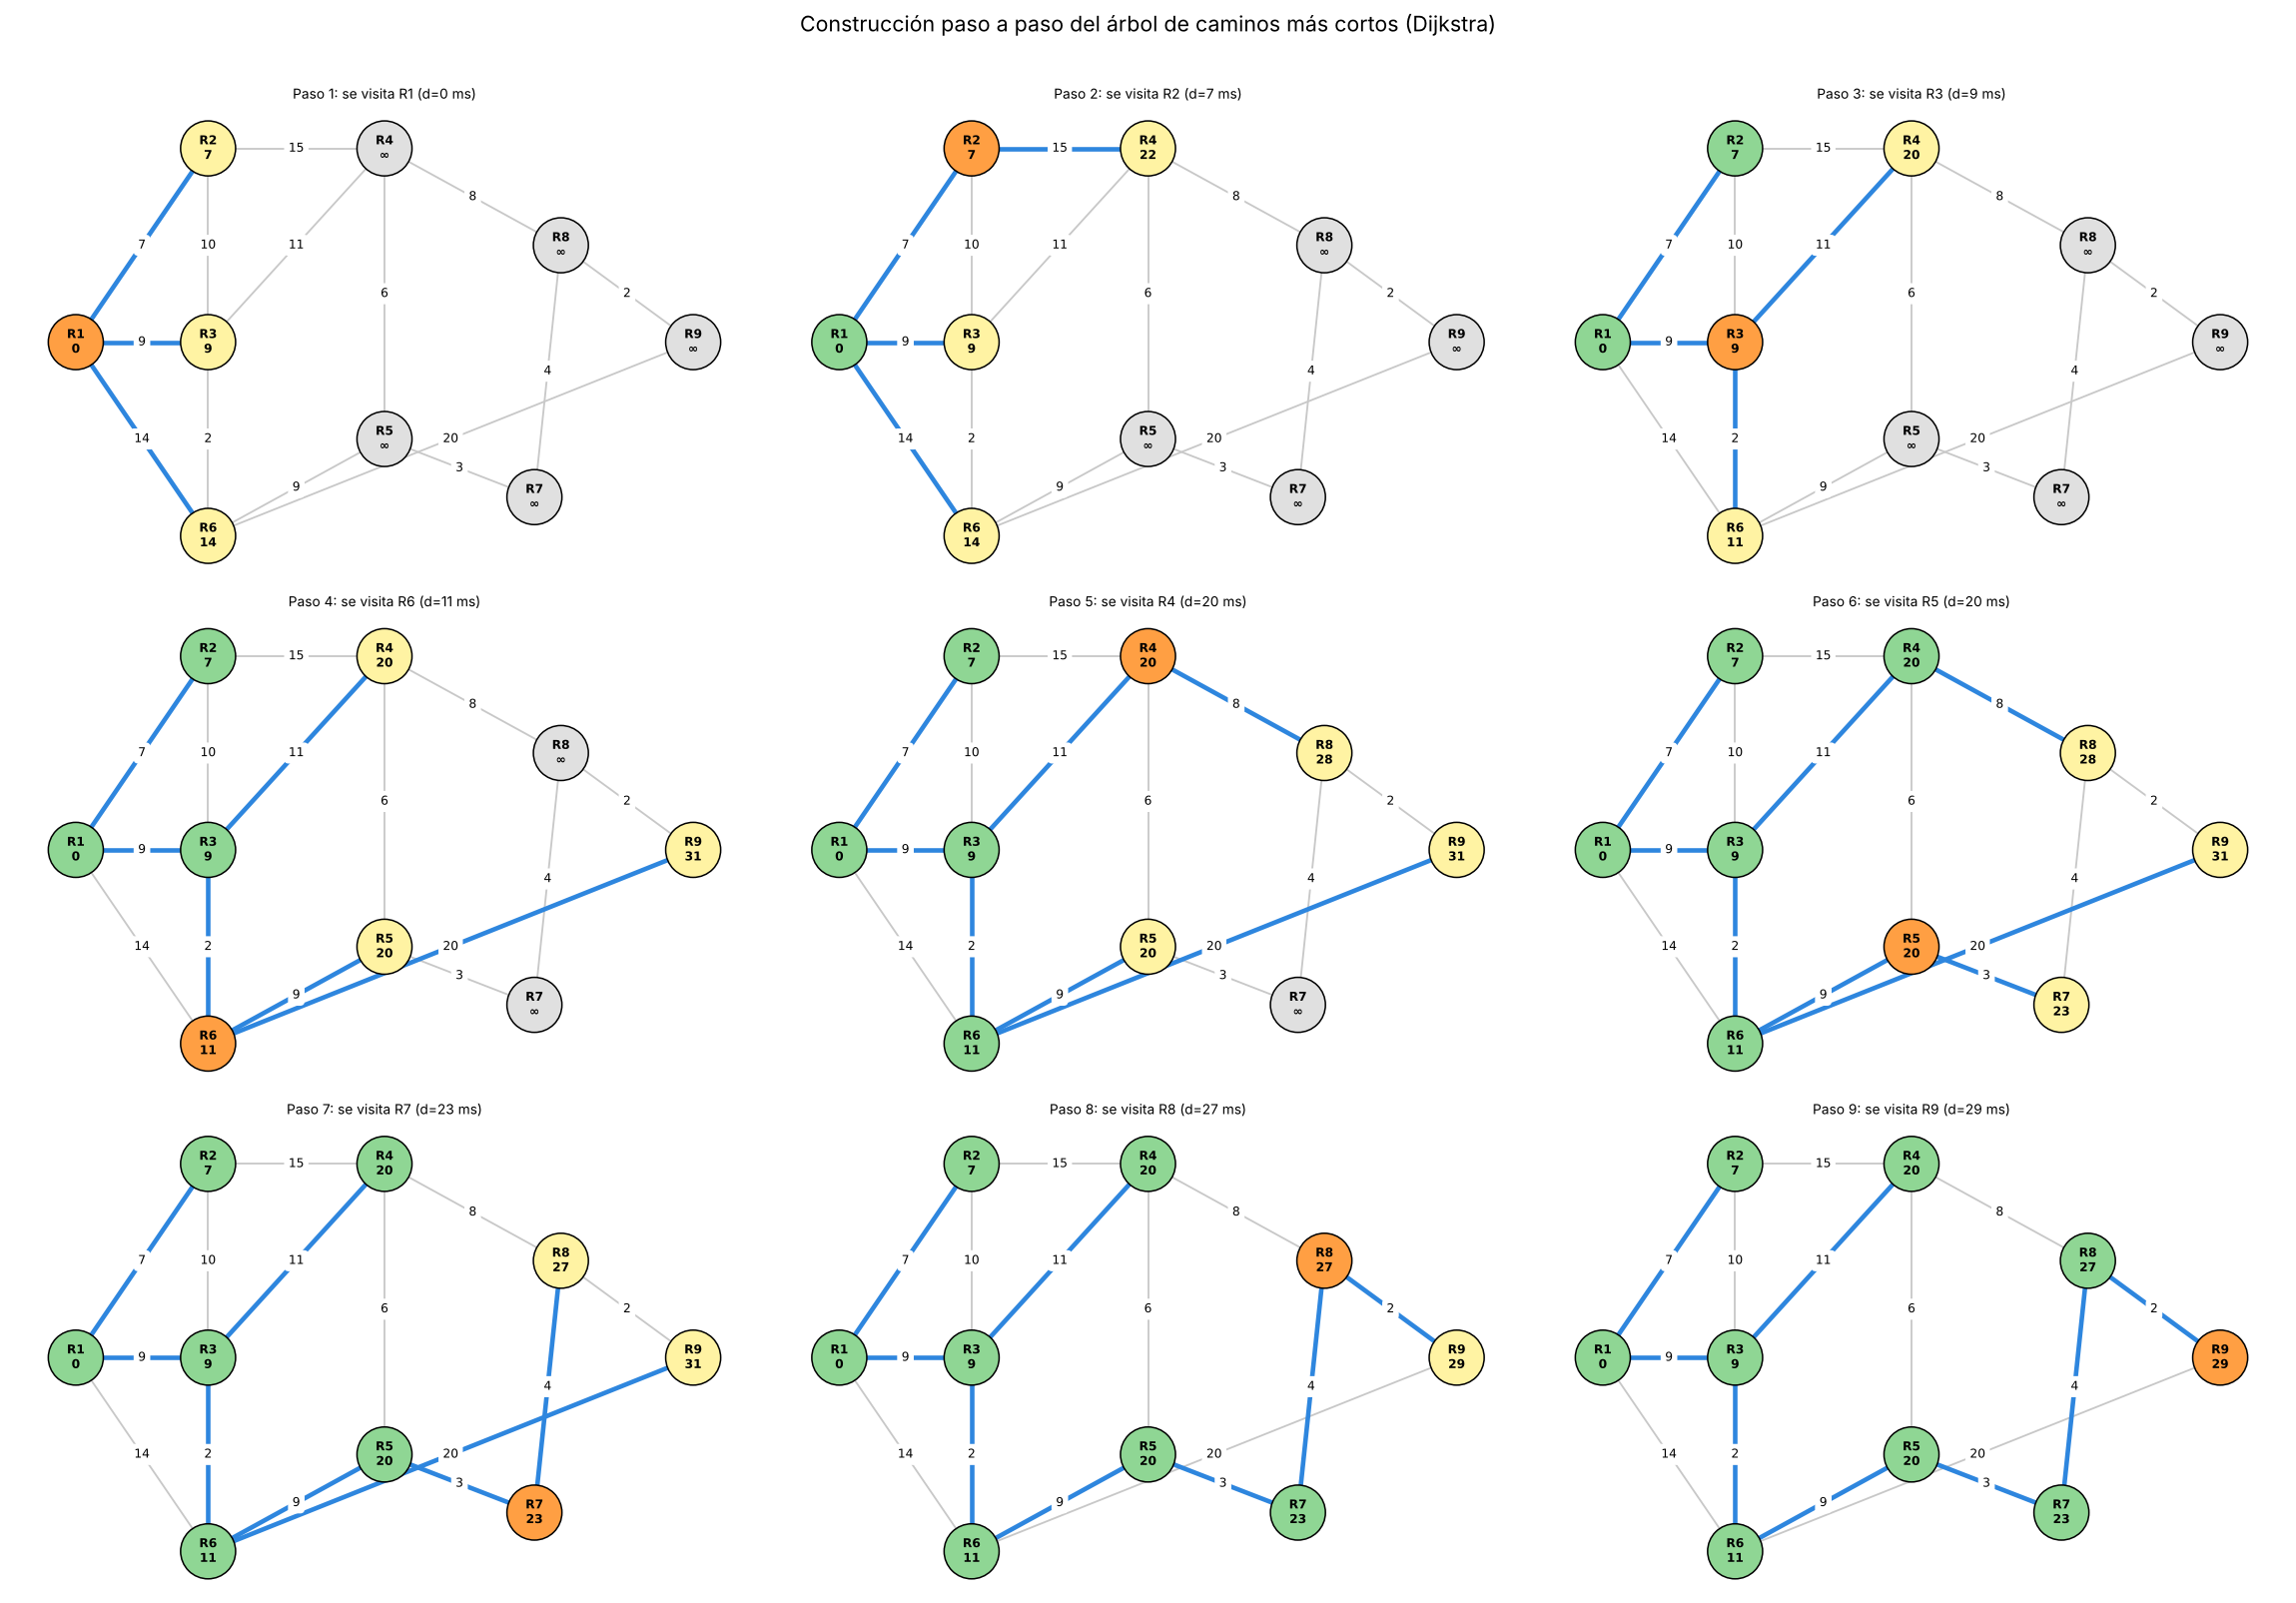

In [25]:
n = len(historial)
cols = 3
filas = math.ceil(n / cols)
fig, axes = plt.subplots(filas, cols, figsize=(7 * cols, 4.8 * filas))
axes = axes.flatten()
for k, (u, d_, vis, arb, dact) in enumerate(historial):
    dibujar_dij(axes[k], G3, pos3, dist=d_, visitados=vis - {u}, actual=u, arbol=arb,
                titulo=f"Paso {k+1}: se visita {u} (d={dact} ms)")
for j in range(n, len(axes)):
    axes[j].axis("off")
plt.suptitle("Construcción paso a paso del árbol de caminos más cortos (Dijkstra)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Paso 3. Reconstrucción de la ruta más corta
Se parte del destino y se siguen los predecesores hacia atrás hasta llegar al origen.

In [26]:
camino = []
nodo = destino
while nodo is not None:
    camino.append(nodo)
    nodo = prev[nodo]
camino.reverse()

aristas_camino = list(zip(camino[:-1], camino[1:]))
print("Ruta más corta:", " → ".join(camino))
print("Detalle de latencias:")
total = 0
for a, b in aristas_camino:
    w = G3[a][b]["weight"]
    total += w
    print(f"   {a} → {b}: {w} ms (acumulado: {total} ms)")
print(f"\nDISTANCIA TOTAL = {total} ms  (d({destino}) = {dist[destino]} ms)")

Ruta más corta: R1 → R3 → R6 → R5 → R7 → R8 → R9
Detalle de latencias:
   R1 → R3: 9 ms (acumulado: 9 ms)
   R3 → R6: 2 ms (acumulado: 11 ms)
   R6 → R5: 9 ms (acumulado: 20 ms)
   R5 → R7: 3 ms (acumulado: 23 ms)
   R7 → R8: 4 ms (acumulado: 27 ms)
   R8 → R9: 2 ms (acumulado: 29 ms)

DISTANCIA TOTAL = 29 ms  (d(R9) = 29 ms)


## 3.7 Resultado final y verificación

Ruta NetworkX:      R1 → R3 → R6 → R5 → R7 → R8 → R9 (29 ms)
Ruta implementada:  R1 → R3 → R6 → R5 → R7 → R8 → R9 (29 ms)
¿Coinciden? True


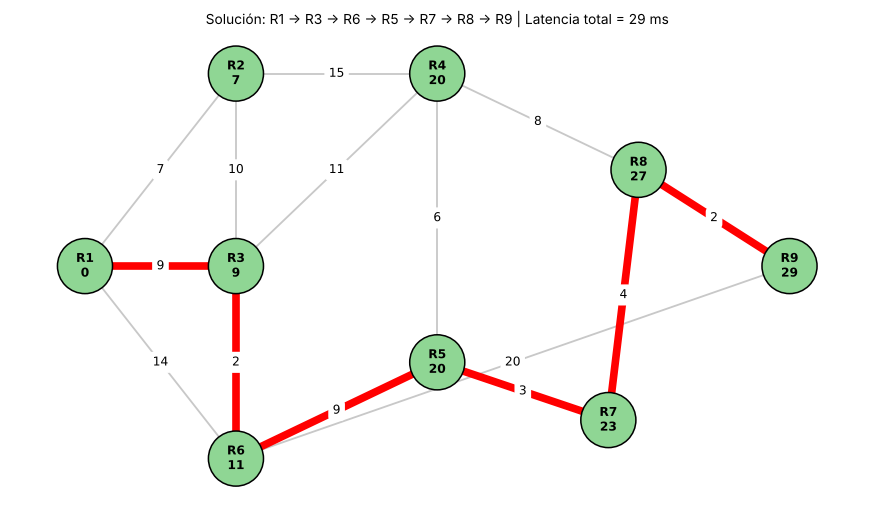

In [27]:
ruta_nx = nx.dijkstra_path(G3, origen, destino, weight="weight")
dist_nx = nx.dijkstra_path_length(G3, origen, destino, weight="weight")
print("Ruta NetworkX:     ", " → ".join(ruta_nx), f"({dist_nx} ms)")
print("Ruta implementada: ", " → ".join(camino), f"({dist[destino]} ms)")
print("¿Coinciden?", ruta_nx == camino and dist_nx == dist[destino])

fig, ax = plt.subplots(figsize=(10, 5.5))
dibujar_dij(ax, G3, pos3, dist=dist, visitados=set(G3.nodes()), camino=aristas_camino,
            titulo=f"Solución: {' → '.join(camino)} | Latencia total = {total} ms")
plt.show()

### Justificación: comparación con rutas alternativas
Para demostrar que la ruta elegida es la mejor, se comparan **todos los caminos simples** entre `R1` y `R9` (la red es pequeña, así que es posible).

Caminos posibles entre R1 y R9: 31


,Ruta,Saltos,Latencia (ms)
0,R1 → R3 → R6 → R5 → R7 → R8 → R9,6,29
1,R1 → R3 → R4 → R8 → R9,4,30
2,R1 → R3 → R6 → R9,3,31
3,R1 → R2 → R4 → R8 → R9,4,32
4,R1 → R6 → R5 → R7 → R8 → R9,5,32
5,R1 → R6 → R9,2,34
6,R1 → R3 → R4 → R5 → R7 → R8 → R9,6,35
7,R1 → R3 → R6 → R5 → R4 → R8 → R9,6,36
8,R1 → R6 → R3 → R4 → R8 → R9,5,37
9,R1 → R2 → R3 → R6 → R5 → R7 → R8 → R9,7,37


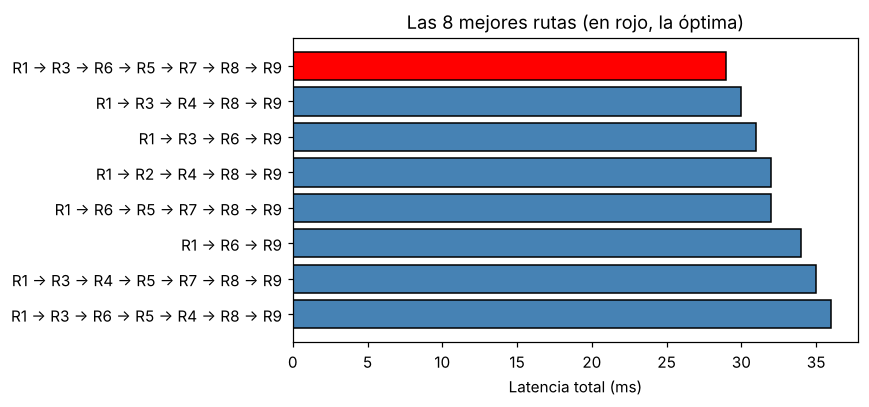

In [28]:
todas = list(nx.all_simple_paths(G3, origen, destino))
filas_ = []
for c in todas:
    costo = sum(G3[a][b]["weight"] for a, b in zip(c[:-1], c[1:]))
    filas_.append((" → ".join(c), len(c) - 1, costo))
df_rutas = pd.DataFrame(filas_, columns=["Ruta", "Saltos", "Latencia (ms)"]).sort_values("Latencia (ms)").reset_index(drop=True)
print(f"Caminos posibles entre {origen} y {destino}: {len(df_rutas)}")
display(df_rutas.head(10))

fig, ax = plt.subplots(figsize=(8, 3.8))
top = df_rutas.head(8)
colores = ["red" if i == 0 else "steelblue" for i in range(len(top))]
ax.barh(top["Ruta"][::-1], top["Latencia (ms)"][::-1], color=colores[::-1], edgecolor="black")
ax.set_xlabel("Latencia total (ms)")
ax.set_title("Las 8 mejores rutas (en rojo, la óptima)")
plt.tight_layout()
plt.show()

## 3.8 Interpretación de resultados y aplicación al área de TI

- La ruta de menor latencia es **R1 → R3 → R6 → R5 → R7 → R8 → R9**, con **29 ms** en total.
- Es una ruta de 6 saltos; la ruta con **menos saltos** (`R1 → R6 → R9`, 34 ms) tiene mayor latencia porque usa enlaces individualmente costosos. Dijkstra minimiza la **suma de pesos**, no el número de saltos.
- La tabla de rutas confirma que ninguna alternativa mejora los 29 ms, lo que valida el resultado (también coincide con `networkx`).
- Dijkstra calcula además la distancia óptima desde `R1` hacia **todos** los routers en una sola ejecución.
- **Aplicaciones en TI:** es la base de los protocolos de enrutamiento de estado de enlace **OSPF** e **IS-IS**, de los sistemas de navegación GPS, del balanceo de carga entre centros de datos y de la selección de rutas en redes definidas por software (SDN). Requisito: los pesos deben ser no negativos; con pesos negativos se usa Bellman-Ford.

<a id="practica4"></a>
---
# PRÁCTICA 4. Programación Lineal

## 4.1 Título del problema
**Asignación de recursos de un servidor para maximizar la utilidad de una empresa de hospedaje en la nube.**

## 4.2 Descripción y planteamiento
Una empresa de servicios en la nube vende dos tipos de máquinas virtuales (VM) montadas sobre un mismo servidor físico:

| | VM Estándar | VM Alto rendimiento | Capacidad disponible |
|---|---|---|---|
| vCPU por VM | 1 | 2 | 80 vCPU |
| RAM por VM (GB) | 4 | 3 | 180 GB |
| Almacenamiento por VM (×100 GB) | 1 | 3 | 90 (= 9 TB) |
| Utilidad mensual por VM (pesos) | 30 | 50 | — |

**Objetivo:** decidir cuántas VM de cada tipo conviene ofrecer para **maximizar la utilidad mensual** sin exceder los recursos del servidor.

## 4.3 Formulación matemática

**Variables de decisión**
- $x_1$ = número de VM Estándar
- $x_2$ = número de VM de Alto rendimiento

**Función objetivo**
$$\max\ Z = 30x_1 + 50x_2$$

**Restricciones**
$$\begin{aligned}
x_1 + 2x_2 &\le 80 && \text{(vCPU)}\\
4x_1 + 3x_2 &\le 180 && \text{(RAM)}\\
x_1 + 3x_2 &\le 90 && \text{(almacenamiento)}\\
x_1,\ x_2 &\ge 0 && \text{(no negatividad)}
\end{aligned}$$

Como son solo dos variables, se puede resolver **gráficamente** (región factible y vértices) y verificar con `scipy.optimize.linprog`.

## 4.4 Definición de datos
Se guardan los coeficientes en forma matricial: $c$ (función objetivo), $A$ (coeficientes de las restricciones) y $b$ (lados derechos).

In [29]:
c = np.array([30, 50])                       # utilidad por VM
A = np.array([[1, 2],                        # vCPU
              [4, 3],                        # RAM
              [1, 3]])                       # almacenamiento
b = np.array([80, 180, 90])
nombres_rest = ["vCPU", "RAM", "Almacenamiento"]

modelo = pd.DataFrame(A, columns=["x1 (Estándar)", "x2 (Alto rend.)"], index=nombres_rest)
modelo["Tipo"] = "≤"
modelo["Capacidad (b)"] = b
print("Función objetivo: max Z = 30·x1 + 50·x2\n")
display(modelo)

Función objetivo: max Z = 30·x1 + 50·x2



,x1 (Estándar),x2 (Alto rend.),Tipo,Capacidad (b)
vCPU,1,2,≤,80
RAM,4,3,≤,180
Almacenamiento,1,3,≤,90


## 4.5 Desarrollo del algoritmo (método gráfico)

### Paso 1. Dibujar cada restricción
Cada desigualdad es un semiplano. Se agregan **una por una** para ver cómo la región factible se va reduciendo. Primero se prepara una malla de puntos y una función de dibujo.

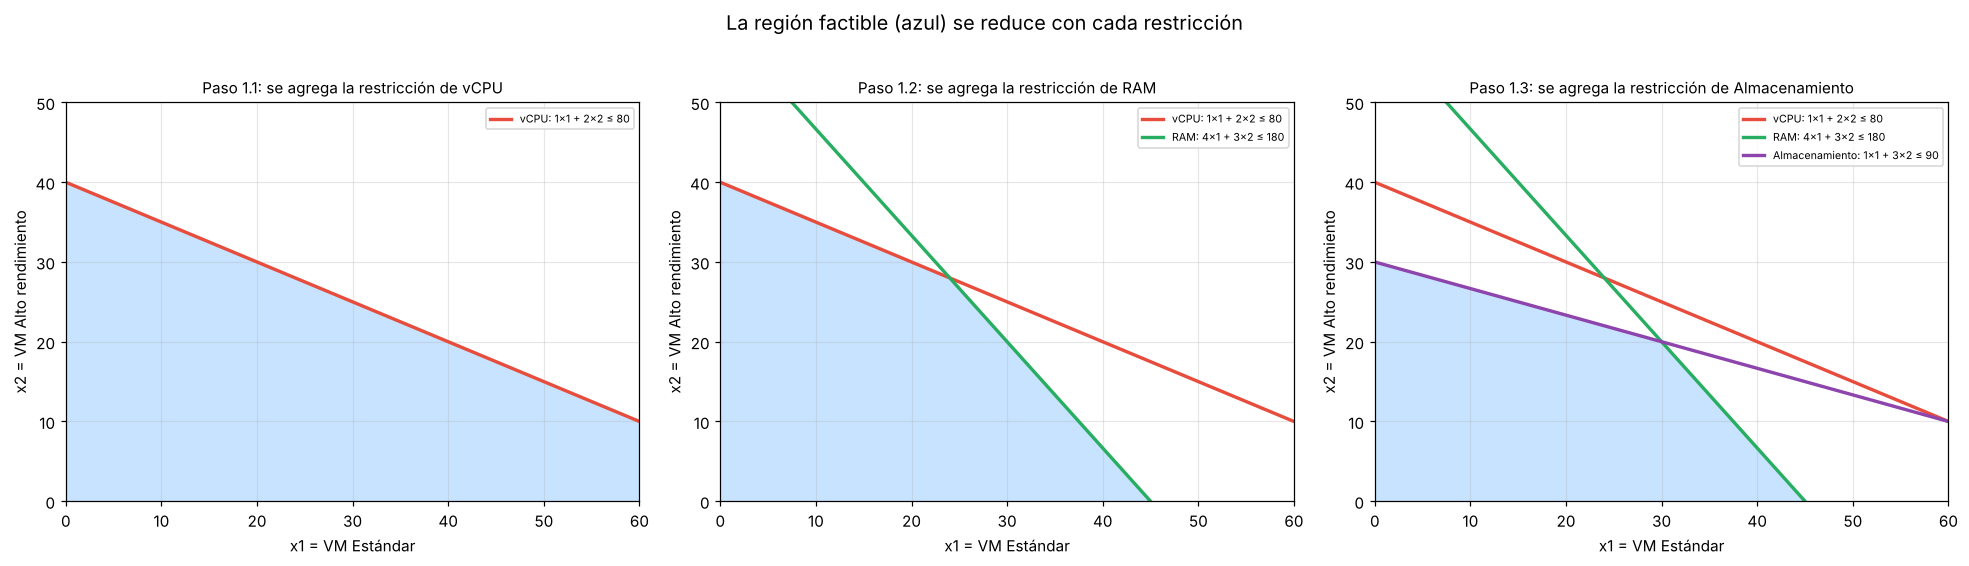

In [30]:
xmax, ymax = 60, 50
xs = np.linspace(0, xmax, 600)
ys = np.linspace(0, ymax, 600)
X1, X2 = np.meshgrid(xs, ys)
colores_rest = ["#e74c3c", "#27ae60", "#8e44ad"]

def base_axes(ax, titulo):
    ax.set_xlim(0, xmax); ax.set_ylim(0, ymax)
    ax.set_xlabel("x1 = VM Estándar"); ax.set_ylabel("x2 = VM Alto rendimiento")
    ax.set_title(titulo, fontsize=10)
    ax.grid(alpha=0.3)

def dibujar_restricciones(ax, k):
    # Dibuja las primeras k restricciones y sombrea la región que cumple todas ellas
    cumple = np.ones_like(X1, dtype=bool)
    for i in range(k):
        a1, a2 = A[i]
        cumple &= (a1 * X1 + a2 * X2 <= b[i] + 1e-9)
        y_lin = (b[i] - a1 * xs) / a2
        ax.plot(xs, y_lin, color=colores_rest[i], lw=2.2,
                label=f"{nombres_rest[i]}: {a1}x1 + {a2}x2 ≤ {b[i]}")
    ax.contourf(X1, X2, cumple.astype(int), levels=[0.5, 1.5], colors=["#74b9ff"], alpha=0.4)
    ax.legend(fontsize=7, loc="upper right")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for k in range(3):
    dibujar_restricciones(axes[k], k + 1)
    base_axes(axes[k], f"Paso 1.{k+1}: se agrega la restricción de {nombres_rest[k]}")
plt.suptitle("La región factible (azul) se reduce con cada restricción", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Paso 2. Encontrar los vértices de la región factible
La solución óptima de un problema de PL siempre está en un **vértice** de la región factible. Los vértices se obtienen intersectando pares de rectas (incluidos los ejes $x_1=0$ y $x_2=0$) y conservando solo los puntos que cumplen **todas** las restricciones.

In [31]:
from itertools import combinations

# Todas las rectas como filas [a1, a2 | rhs]: las 3 restricciones + los ejes
rectas = [(A[i], b[i]) for i in range(3)] + [(np.array([1, 0]), 0), (np.array([0, 1]), 0)]
candidatos = []
print("Intersecciones de pares de rectas:")
for (r1, b1), (r2, b2) in combinations(rectas, 2):
    M = np.array([r1, r2], dtype=float)
    if abs(np.linalg.det(M)) < 1e-12:
        continue                                   # rectas paralelas
    p = np.linalg.solve(M, [b1, b2])
    factible = bool(np.all(A @ p <= b + 1e-9) and np.all(p >= -1e-9))
    print(f"   {np.round(p, 3)}  →  {'factible ✔' if factible else 'no factible ✘'}")
    if factible:
        candidatos.append(tuple(np.round(p, 6)))

vertices = sorted(set(candidatos))
print("\nVértices de la región factible:", vertices)

Intersecciones de pares de rectas:
   [24. 28.]  →  no factible ✘
   [60. 10.]  →  no factible ✘
   [ 0. 40.]  →  no factible ✘
   [80.  0.]  →  no factible ✘
   [30. 20.]  →  factible ✔
   [ 0. 60.]  →  no factible ✘
   [45.  0.]  →  factible ✔
   [ 0. 30.]  →  factible ✔
   [90.  0.]  →  no factible ✘
   [0. 0.]  →  factible ✔

Vértices de la región factible: [(np.float64(0.0), np.float64(0.0)), (np.float64(0.0), np.float64(30.0)), (np.float64(30.0), np.float64(20.0)), (np.float64(45.0), np.float64(0.0))]


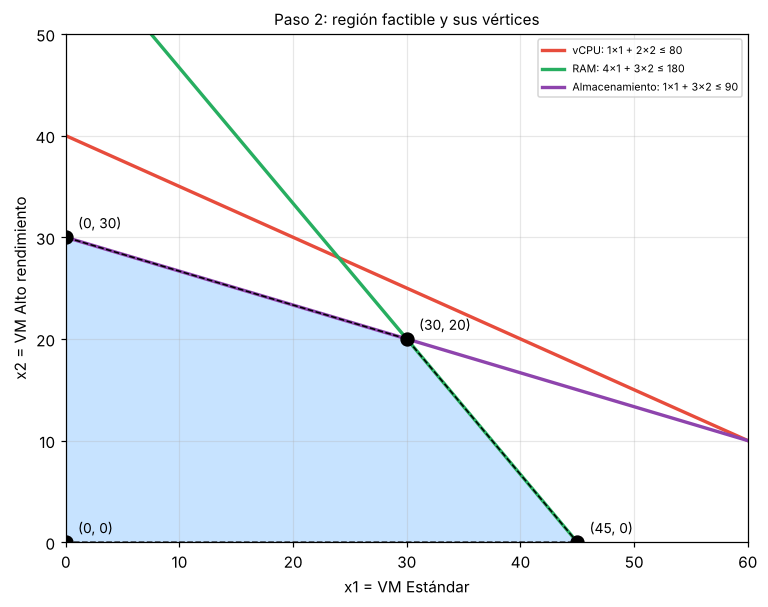

In [32]:
# Ordenar los vértices alrededor del centroide para poder dibujar el polígono
V = np.array(vertices)
centro = V.mean(axis=0)
ang = np.arctan2(V[:, 1] - centro[1], V[:, 0] - centro[0])
V = V[np.argsort(ang)]

fig, ax = plt.subplots(figsize=(8, 6))
dibujar_restricciones(ax, 3)
ax.fill(V[:, 0], V[:, 1], color="#74b9ff", alpha=0.0)
ax.plot(*np.vstack([V, V[0]]).T, "k--", lw=1)
ax.scatter(V[:, 0], V[:, 1], color="black", s=70, zorder=5)
for (x1, x2) in V:
    ax.annotate(f"({x1:g}, {x2:g})", (x1, x2), textcoords="offset points", xytext=(8, 6), fontsize=9)
base_axes(ax, "Paso 2: región factible y sus vértices")
plt.show()

### Paso 3. Evaluar la función objetivo en cada vértice
Se calcula $Z=30x_1+50x_2$ en cada vértice; el mayor valor es el óptimo.

In [33]:
tabla_v = pd.DataFrame(V, columns=["x1", "x2"])
tabla_v["Z = 30·x1 + 50·x2"] = tabla_v["x1"] * 30 + tabla_v["x2"] * 50
tabla_v = tabla_v.sort_values("Z = 30·x1 + 50·x2", ascending=False).reset_index(drop=True)
display(tabla_v)

mejor = tabla_v.iloc[0]
print(f"Mejor vértice: x1 = {mejor['x1']:g}, x2 = {mejor['x2']:g}  →  Z = {mejor.iloc[2]:g}")

,x1,x2,Z = 30·x1 + 50·x2
0,30.0,20.0,1900.0
1,0.0,30.0,1500.0
2,45.0,0.0,1350.0
3,0.0,0.0,0.0


Mejor vértice: x1 = 30, x2 = 20  →  Z = 1900


### Paso 4. Líneas de isoutilidad
Una recta $30x_1+50x_2=k$ une todos los puntos con la misma utilidad $k$. Al aumentar $k$ la recta se desplaza hacia arriba y a la derecha; el **último punto factible que toca** es el óptimo.

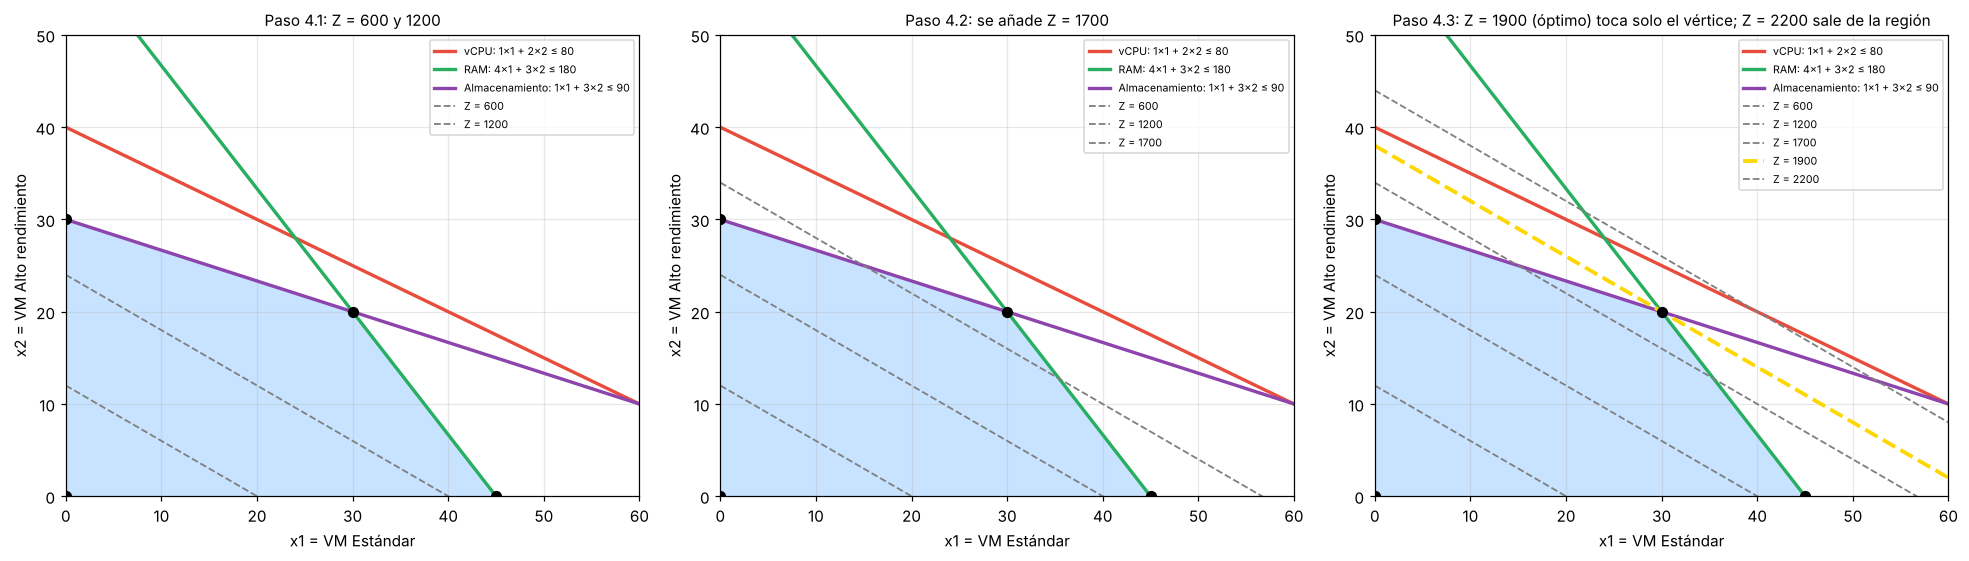

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
niveles_z = [[600, 1200], [600, 1200, 1700], [600, 1200, 1700, 1900, 2200]]
titulos = ["Paso 4.1: Z = 600 y 1200", "Paso 4.2: se añade Z = 1700",
           "Paso 4.3: Z = 1900 (óptimo) toca solo el vértice; Z = 2200 sale de la región"]
for ax, zs, t in zip(axes, niveles_z, titulos):
    dibujar_restricciones(ax, 3)
    for z in zs:
        y_iso = (z - 30 * xs) / 50
        optimo = z == 1900
        ax.plot(xs, y_iso, "--", lw=2.5 if optimo else 1.2, color="gold" if optimo else "gray",
                label=f"Z = {z}")
    ax.scatter(V[:, 0], V[:, 1], color="black", s=40, zorder=5)
    ax.legend(fontsize=7, loc="upper right")
    base_axes(ax, t)
plt.tight_layout()
plt.show()

## 4.6 Solución con Python (`scipy.optimize.linprog`)
`linprog` **minimiza** por defecto, así que para maximizar $Z$ se minimiza $-Z$ (se usa el vector `-c`) y al final se cambia el signo del resultado. Se usa el método `highs` (simplex / punto interior de alto rendimiento).

In [35]:
res = linprog(c=-c, A_ub=A, b_ub=b, bounds=[(0, None), (0, None)], method="highs")

print("Mensaje del solver:", res.message)
print("¿Éxito?:", res.success)
print(f"\nx1 (VM Estándar)        = {res.x[0]:.4f}")
print(f"x2 (VM Alto rendimiento) = {res.x[1]:.4f}")
print(f"Utilidad máxima Z        = {-res.fun:.2f} pesos/mes")

Mensaje del solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)
¿Éxito?: True

x1 (VM Estándar)        = 30.0000
x2 (VM Alto rendimiento) = 20.0000
Utilidad máxima Z        = 1900.00 pesos/mes


### Análisis de holguras y precios sombra
- **Holgura (slack):** recursos que **sobran**. Una restricción con holgura 0 es **activa** (se agota el recurso).
- **Precio sombra:** cuánto aumentaría $Z$ por cada **unidad adicional** de ese recurso (mientras la base óptima no cambie).

,Recurso,Capacidad,Uso,Holgura,¿Activa?,Precio sombra
0,vCPU,80,70.0,10.0,no (sobra),0.0000
1,RAM,180,180.0,0.0,SÍ (agotado),4.4444
2,Almacenamiento,90,90.0,0.0,SÍ (agotado),12.2222


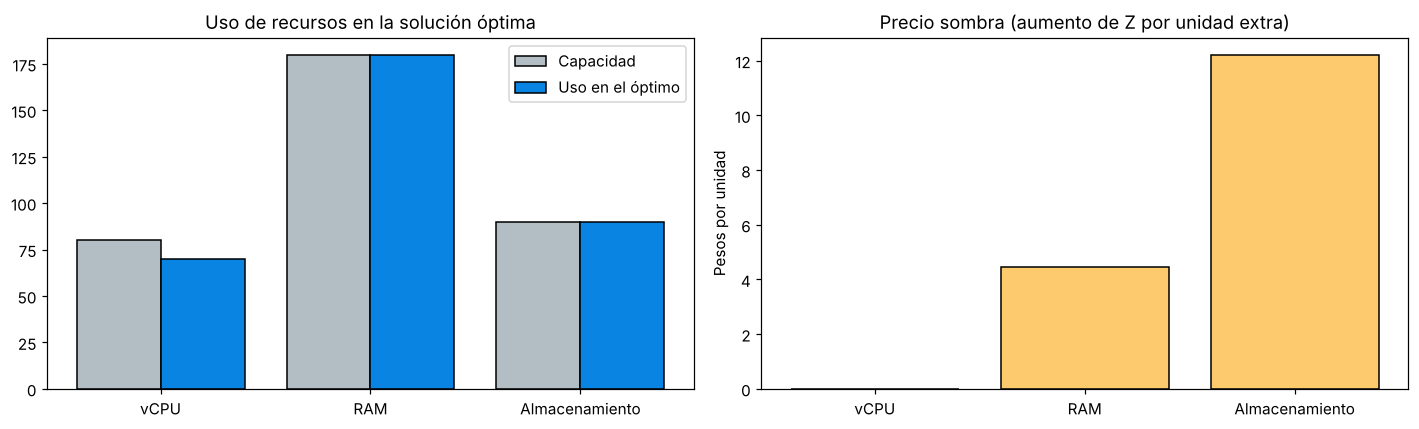

In [36]:
uso = A @ res.x
precio_sombra = -res.ineqlin.marginals      # signo invertido porque se minimizó -Z

analisis = pd.DataFrame({
    "Recurso": nombres_rest,
    "Capacidad": b,
    "Uso": np.round(uso, 4),
    "Holgura": np.round(res.slack, 4),
    "¿Activa?": ["SÍ (agotado)" if s < 1e-7 else "no (sobra)" for s in res.slack],
    "Precio sombra": np.round(precio_sombra, 4),
})
display(analisis)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x_pos = np.arange(3)
axes[0].bar(x_pos - 0.2, b, 0.4, label="Capacidad", color="#b2bec3", edgecolor="black")
axes[0].bar(x_pos + 0.2, uso, 0.4, label="Uso en el óptimo", color="#0984e3", edgecolor="black")
axes[0].set_xticks(x_pos); axes[0].set_xticklabels(nombres_rest)
axes[0].set_title("Uso de recursos en la solución óptima"); axes[0].legend()
axes[1].bar(nombres_rest, precio_sombra, color="#fdcb6e", edgecolor="black")
axes[1].set_title("Precio sombra (aumento de Z por unidad extra)")
axes[1].set_ylabel("Pesos por unidad")
plt.tight_layout()
plt.show()

## 4.7 Visualización de la solución óptima

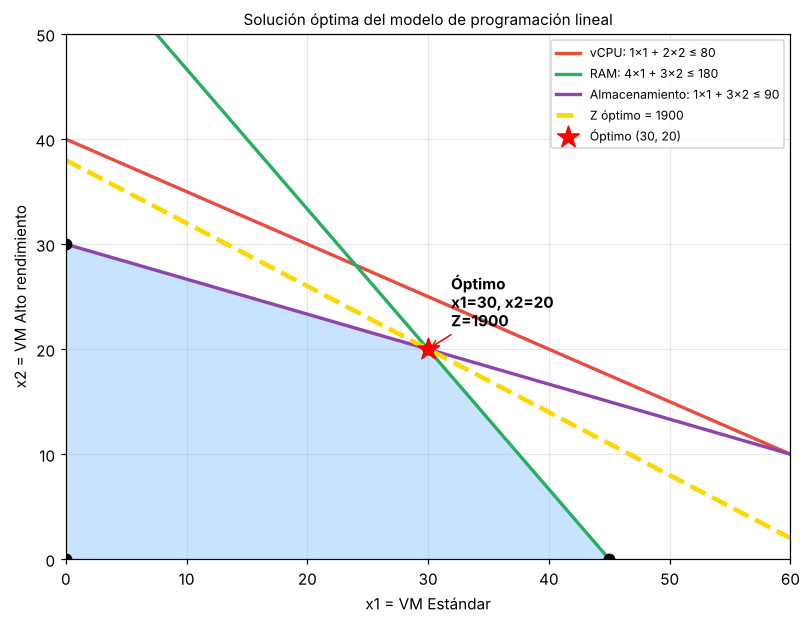

¿Coincide el método gráfico con linprog? True


In [37]:
fig, ax = plt.subplots(figsize=(8.5, 6.2))
dibujar_restricciones(ax, 3)
z_opt = -res.fun
ax.plot(xs, (z_opt - 30 * xs) / 50, color="gold", lw=3, ls="--", label=f"Z óptimo = {z_opt:g}")
ax.scatter(V[:, 0], V[:, 1], color="black", s=45, zorder=5)
ax.scatter(*res.x, color="red", s=220, marker="*", zorder=6, label=f"Óptimo ({res.x[0]:g}, {res.x[1]:g})")
ax.annotate(f"Óptimo\nx1={res.x[0]:g}, x2={res.x[1]:g}\nZ={z_opt:g}", res.x, textcoords="offset points",
            xytext=(15, 15), fontsize=10, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="red"))
ax.legend(fontsize=8, loc="upper right")
base_axes(ax, "Solución óptima del modelo de programación lineal")
plt.show()

print("¿Coincide el método gráfico con linprog?",
      np.allclose(res.x, [mejor['x1'], mejor['x2']]) and np.isclose(-res.fun, mejor.iloc[2]))

## 4.8 Interpretación de resultados y aplicación al área de TI

- **Solución óptima:** ofrecer **30 VM Estándar** y **20 VM de Alto rendimiento**, con una utilidad máxima de **\$1 900 al mes**. El método gráfico y `linprog` coinciden.
- **Recursos agotados (restricciones activas):** la **RAM** (4·30 + 3·20 = 180) y el **almacenamiento** (30 + 3·20 = 90). Son los **cuellos de botella** del servidor.
- **Recurso sobrante:** los **vCPU** se usan 70 de 80, es decir, **10 vCPU sin utilizar**. Su precio sombra es 0: comprar más CPU no aumentaría la utilidad.
- **Precios sombra:** cada GB adicional de RAM aumentaría Z en ≈ \$4.44 y cada unidad adicional de almacenamiento (100 GB) en ≈ \$12.22. Es decir, **conviene invertir en almacenamiento y RAM, no en CPU**, mientras no cambie la base óptima.
- **Aplicaciones en TI:** dimensionamiento de capacidad en nubes y centros de datos, asignación de tareas a servidores, planificación de recursos en clústeres, mezcla de productos o servicios, y optimización de ancho de banda y costos de infraestructura.

<a id="conclusiones"></a>
---
# Resumen comparativo de las cuatro prácticas

In [38]:
resumen = pd.DataFrame({
    "Práctica": ["1. Expansión mínima (Kruskal)", "2. Ruta crítica (CPM)", "3. Dijkstra", "4. Programación lineal"],
    "Tipo de problema": ["Conectar todos los nodos al menor costo", "Duración mínima y actividades críticas",
                         "Camino más corto entre dos nodos", "Maximizar utilidad con recursos limitados"],
    "Resultado": [f"Costo mínimo = {costo_total} (7 enlaces)",
                  f"Duración = {D} días; ruta: {'-'.join(criticas)}",
                  f"Latencia = {dist[destino]} ms; ruta: {'-'.join(camino)}",
                  f"Z = {-res.fun:g}; x1 = {res.x[0]:g}, x2 = {res.x[1]:g}"],
    "Aplicación en TI": ["Cableado y STP", "Gestión de proyectos de software", "Enrutamiento OSPF", "Capacidad en la nube"],
})
display(resumen.style.hide(axis="index"))

Práctica,Tipo de problema,Resultado,Aplicación en TI
1. Expansión mínima (Kruskal),Conectar todos los nodos al menor costo,Costo mínimo = 23 (7 enlaces),Cableado y STP
2. Ruta crítica (CPM),Duración mínima y actividades críticas,Duración = 23 días; ruta: A-B-E-G-H-J-K,Gestión de proyectos de software
3. Dijkstra,Camino más corto entre dos nodos,Latencia = 29 ms; ruta: R1-R3-R6-R5-R7-R8-R9,Enrutamiento OSPF
4. Programación lineal,Maximizar utilidad con recursos limitados,"Z = 1900; x1 = 30, x2 = 20",Capacidad en la nube


# Conclusiones individuales y del equipo

> **Nota:** esta sección debe redactarse con las palabras de cada integrante antes de entregar. A continuación se deja una conclusión base y los espacios para completar.

## Conclusión individual — Karla Isabel Bautista Santillán
Con esta actividad comprendí que los modelos de Investigación de Operaciones no son solo teoría: se pueden implementar y *ver* funcionar. Graficar cada paso de Kruskal, de la pasada hacia adelante y atrás del CPM, de las iteraciones de Dijkstra y de la región factible en programación lineal me ayudó a entender **por qué** cada algoritmo toma sus decisiones y no solo cuál es el resultado final. También comprobé la importancia de **validar** los resultados contra una herramienta ya probada (NetworkX y SciPy).

*(Edita este párrafo con tu propia reflexión: qué práctica te resultó más difícil, qué aprendiste, cómo lo conectas con tu carrera.)*

## Conclusiones de los demás integrantes
*(Integrante 2: …)*  
*(Integrante 3: …)*

## Conclusión del equipo
Los cuatro modelos comparten una idea central: **tomar la mejor decisión posible dentro de restricciones**. Kruskal minimiza el costo de conectar una red, CPM identifica dónde no hay margen en un proyecto, Dijkstra encuentra el camino de menor costo y la programación lineal reparte recursos limitados para maximizar un beneficio. Todos tienen aplicación directa en Tecnologías de la Información: diseño de redes, gestión de proyectos de software, enrutamiento y dimensionamiento de infraestructura. Documentar el proceso con Markdown y ejecutar el código línea por línea permitió evidenciar el procedimiento completo y no solo el resultado.

---
### Recordatorio de entrega
- [ ] Archivo `.ipynb` (este notebook, ejecutado con todas sus salidas)
- [ ] Reporte exportado en PDF (*File → Save and Export Notebook As → PDF*, o imprimir desde el navegador)
- [ ] Archivos complementarios utilizados
- [ ] Evidencias de ejecución
- [ ] **Subir las cuatro prácticas al repositorio de GitHub "Investigacion de Operaciones" de cada integrante** (si algún integrante no sube sus evidencias, no se cuenta el trabajo)